In [1]:
!rm -rf magiclens
!git clone https://github.com/google-deepmind/magiclens.git
%cd magiclens
!ls

Cloning into 'magiclens'...
remote: Enumerating objects: 44, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 44 (delta 17), reused 35 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (44/44), 27.07 KiB | 3.38 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/kaggle/working/magiclens
CONTRIBUTING.md  data_utils.py	layers.py  model.py
data		 inference.py	LICENSE    README.md


In [2]:
# Cài đặt Scenic (thư viện nền cho các mô hình Vision của Google)
!git clone https://github.com/google-research/scenic.git
%cd scenic
!pip install .
!pip install -r scenic/projects/baselines/clip/requirements.txt
%cd ..

# Cài đặt các thư viện cần thiết khác
!pip install -q ftfy ml_collections

Cloning into 'scenic'...
remote: Enumerating objects: 11967, done.
remote: Counting objects: 100% (2276/2276), done.
remote: Compressing objects: 100% (405/405), done.
remote: Total 11967 (delta 2065), reused 1875 (delta 1871), pack-reused 9691 (from 2)
Receiving objects: 100% (11967/11967), 65.08 MiB | 32.07 MiB/s, done.
Resolving deltas: 100% (8840/8840), done.
/kaggle/working/magiclens/scenic
Processing /kaggle/working/magiclens/scenic
  Preparing metadata (setup.py) ... done
  Cloning https://github.com/google-deepmind/optax.git (to revision main) to /tmp/pip-install-e2q3ilo1/optax_495625903db64a709e1c2476f5ec3ec9
  Running command git clone --filter=blob:none --quiet https://github.com/google-deepmind/optax.git /tmp/pip-install-e2q3ilo1/optax_495625903db64a709e1c2476f5ec3ec9
  Resolved https://github.com/google-deepmind/optax.git to commit bbd466e786f9c1ba05aecd6ce1bf04d1a8e790bf
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing me

In [3]:
# Tạo thư mục chứa model
!mkdir -p ./magiclens_models

# Tải bản Base (khoảng vài GB)
!gsutil -m cp -R gs://gresearch/magiclens/models ./magiclens_models/

Copying gs://gresearch/magiclens/models/magic_lens_clip_base.pkl...
Copying gs://gresearch/magiclens/models/magic_lens_clip_large.pkl...
==> NOTE: You are downloading one or more large file(s), which would
run significantly faster if you enabled sliced object downloads. This
feature is enabled by default but requires that compiled crcmod be
installed (see "gsutil help crcmod").


Operation completed over 2 objects/2.4 GiB.                                      


In [4]:
!gsutil cp gs://gresearch/magiclens/models/magic_lens_clip_base.pkl /kaggle/working/magiclens/

Copying gs://gresearch/magiclens/models/magic_lens_clip_base.pkl...
==> NOTE: You are downloading one or more large file(s), which would
run significantly faster if you enabled sliced object downloads. This
feature is enabled by default but requires that compiled crcmod be
installed (see "gsutil help crcmod").


Operation completed over 1 objects/634.9 MiB.                                    


In [5]:
!pip install -q git+https://github.com/google-research/scenic.git
!pip install -q ml_collections ftfy

  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [6]:
import os
import sys
import importlib.util

# 1. Đường dẫn tuyệt đối đến thư mục chứa code
REPO_PATH = '/kaggle/working/magiclens'

# 2. Đưa đường dẫn vào sys.path để các file nội bộ thấy nhau
if REPO_PATH not in sys.path:
    sys.path.insert(0, REPO_PATH)

# 3. Hàm ép nạp file .py thành module
def force_import(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

try:
    # Nạp layers.py trước (vì model.py phụ thuộc vào nó)
    force_import('layers', os.path.join(REPO_PATH, 'layers.py'))
    # Nạp data_utils.py (vì inference.py phụ thuộc vào nó)
    force_import('data_utils', os.path.join(REPO_PATH, 'data_utils.py'))
    # Nạp model.py
    force_import('model', os.path.join(REPO_PATH, 'model.py'))
    # Nạp inference.py
    force_import('inference', os.path.join(REPO_PATH, 'inference.py'))

    from inference import load_model
    print("✅ THÀNH CÔNG! Đã nạp được toàn bộ module.")

    # 4. Tải và Load checkpoint
    model_path = os.path.join(REPO_PATH, 'magic_lens_clip_base.pkl')
    if not os.path.exists(model_path):
        !gsutil cp gs://gresearch/magiclens/models/magic_lens_clip_base.pkl {model_path}

    model_dict = load_model('base', model_path)
    print("🚀 Model đã sẵn sàng!")

except Exception as e:
    print(f"❌ Vẫn kẹt ở: {e}")

2026-07-05 15:42:10.915212: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783266131.337412      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783266131.435962      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1783266132.471867      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1783266132.471913      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1783266132.471917      24 computation_placer.cc:177] computation placer alr

✅ THÀNH CÔNG! Đã nạp được toàn bộ module.
model initialized
model loaded
🚀 Model đã sẵn sàng!


In [7]:
from datasets import load_dataset
from huggingface_hub import hf_hub_download
import os
from zipfile import ZipFile
from PIL import Image

# 1. Load products and reviews datasets
products = load_dataset("allietran/CAMEO", "products", split="test")
reviews = load_dataset("allietran/CAMEO", "reviews", split="test")
sample = products[0]
relative_path = sample["image_path"]

README.md: 0.00B [00:00, ?B/s]

products.parquet:   0%|          | 0.00/5.99M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4086 [00:00<?, ? examples/s]

reviews.parquet:   0%|          | 0.00/29.3M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/387034 [00:00<?, ? examples/s]

In [8]:
import os
import pandas as pd

new_base_path = "/kaggle/input/datasets/quanglapnguyen/cameo-images/cameo_images/"
df_products = pd.DataFrame(products)

def fix_path(old_path, base_folder):
    filename_ext = os.path.basename(old_path)
    file_id = os.path.basename(old_path).split('.')[0]
    # Các trường hợp ưu tiên: .jpg -> _v_thumb.jpg -> đổi đuôi mp4
    potential_names = [
        f"{file_id}.jpg",
        f"{file_id}_v_thumb.jpg",
        filename_ext.replace('.mp4', '.jpg') 
    ]
    
    for name in potential_names:
        full_path = os.path.join(base_folder, name)
        if os.path.exists(full_path):
            return full_path
            
    # Trường hợp tên file ID1_ID2.jpg (tìm kiếm theo prefix)
    try:
        all_files = os.listdir(base_folder)
        for f in all_files:
            if f.startswith(file_id) and f.lower().endswith(('.jpg', '.jpeg', '.png')):
                return os.path.join(base_folder, f)
    except:
        pass
        
    return None

df_products['full_image_path'] = df_products['image_path'].apply(lambda x: fix_path(x, new_base_path))

df_products_clean = df_products.dropna(subset=['full_image_path']).reset_index(drop=True)

print(f"✅ Đã khớp xong! Tìm thấy {len(df_products_clean)} ảnh thực tế.")
if len(df_products_clean) > 0:
    print(f"📍 Ví dụ đường dẫn chuẩn: {df_products_clean.iloc[0]['full_image_path']}")

✅ Đã khớp xong! Tìm thấy 4030 ảnh thực tế.
📍 Ví dụ đường dẫn chuẩn: /kaggle/input/datasets/quanglapnguyen/cameo-images/cameo_images/111138057_8587034871.jpg


In [9]:
df_products

,product_id,shop_id,brand,image_path,price,processed_description,product_name,variation,origin,translated_brand,translated_description,translated_name,translated_variation,translated_origin,full_image_path
0,0,0,Simple,images/11/11/111138057_8587034871.jpg,99000,ưu điểm nổi trội sữa rửa mặt simple lành tính ...,Sữa rửa mặt Simple lành tính sạch thoáng - cho...,one_variation,Ba Lan,Simple,Outstanding Advantages: Simple Facial Cleanser...,Simple Gentle & Refreshing Facial Cleanser - f...,one_variation,Poland,/kaggle/input/datasets/quanglapnguyen/cameo-im...
1,1,0,Simple,images/11/11/111138057_8287055694.jpg,99000,ưu điểm nổi trội sữa rửa mặt simple giúp kiềm ...,Sữa rửa mặt Simple giúp kiềm dầu và ngừa mụn h...,one_variation,Ba Lan,Simple,Outstanding features: Simple facial cleanser h...,Simple Face Wash effectively controls oil and ...,one_variation,Poland,/kaggle/input/datasets/quanglapnguyen/cameo-im...
2,2,1,Skin&Dr,images/21/08/21080428_9335942418.mp4,244000,sữa rửa mặt nam skin dr tràm trà 80 g cho da m...,Sữa rửa mặt nam 30Shine phân phối chính hãng S...,"Phiên bản 2022 (80g), Phiên bản 2023(100g)",Hàn Quốc,Skin&Dr,Skin Dr Tea Tree Men's Facial Cleanser 80g for...,"30Shine Men's Face Wash, genuine Skin&dr Tea T...","2022 version (80g), Version 2023(100g)",South Korea,/kaggle/input/datasets/quanglapnguyen/cameo-im...
3,3,2,RHYS MAN,images/75/81/758111427_19601743242.mp4,119000,chính hãng sữa rửa mặt nam rhys man rhys cocon...,Sữa rửa mặt nam RHYS MAN Rhys Coconut Fresh hư...,one_variation,Việt Nam,RHYS MAN,Genuine Rhys Man Rhys Coconut Fresh Men's Faci...,RHYS MAN Rhys Men's Facial Cleanser Coconut Fr...,one_variation,Vietnam,None
4,4,3,SENANA,images/10/76/107632788_3330988133.jpg,9900,sỉ tốt 13 k c bao giá sl toàn quốc ngại j khôn...,🌈🍒🍭 Sữa Rửa Mặt Senana Lấy Sạch Bụi Bẩn Giúp D...,one_variation,no_origin,SENANA,"Great wholesale price, only 13k! Best price gu...",🌈🍒🍭 Senana Facial Cleanser Deeply Cleanses Dir...,one_variation,no_origin,/kaggle/input/datasets/quanglapnguyen/cameo-im...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4081,tiki_1826,tikishop_213,Mihoo,images/18/26/tiki_1826_tikishop_213_big.jpg,25000,Bông Tẩy Trang Mihoo Hàn Quốc - Bông Tròn 80 M...,Bông Tẩy Trang Mihoo Hộp 80 Miếng Bông Tròn,None,None,Mihoo,The Korean Mihoo Pages - 80 pieces of material...,Mihoo Pages Box 80 Pieces of Round Rolls,None,None,/kaggle/input/datasets/quanglapnguyen/cameo-im...
4082,tiki_1827,tikishop_249,MINISO,images/18/27/tiki_1827_tikishop_249_big.jpg,39000,Hộp bông tẩy trang Miniso 2in1 475 miếng (400 ...,Hộp bông tẩy trang Miniso 2in1 475 miếng (400 ...,None,Trung Quốc,MINISO,Miniso 2in 1150 pieces (400 slices of one laye...,Miniso 2in1 7000 pieces (400 slices of a layer...,None,China,/kaggle/input/datasets/quanglapnguyen/cameo-im...
4083,tiki_1828,tikishop_52,Aura,images/18/28/tiki_1828_tikishop_52_big.jpg,129000,Combo Bông Tẩy Trang Aura Beauty 150 Miếng100%...,Combo 5 bông tẩy trang Aura Beauty 150 miếng,None,Nga,Aura,The Aura Beauty Pages are 150 pounds of 100 pe...,Combo 5 Aura Beauty 150 pieces.,None,Russia,/kaggle/input/datasets/quanglapnguyen/cameo-im...
4084,tiki_1829,tikishop_52,Ipek,images/18/29/tiki_1829_tikishop_52_big.jpg,65000,-Bông tẩy trang Ipekthành phần 100% bông cotto...,Combo Bông Tẩy Trang IPEK 150 Miếng (Thổ Nhĩ Kì),None,None,Ipek,- The IPek page wiper is 100 percent cotton co...,IPBM Pages 150 pieces,None,None,/kaggle/input/datasets/quanglapnguyen/cameo-im...


In [10]:
import jax
print(jax.devices())

[CudaDevice(id=0)]


In [11]:
from functools import partial
import jax

@jax.jit
def fast_extract(variables, batch):
    return model_obj.apply(variables, batch)['multimodal_embed_norm']

In [12]:
import os
import numpy as np
import jax.numpy as jnp
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import joblib

class MagicLensSearcher:
    def __init__(self, model_obj, variables, tokenizer, image_folder):
        self.model = model_obj
        self.variables = variables
        self.tokenizer = tokenizer
        self.image_folder = image_folder
        self.all_vectors = None
        self.image_paths = []

    def _get_vec(self, img_obj, text=""):
        img_input = np.array(img_obj.resize((224, 224))) / 255.0
        tokens = self.tokenizer(text) 
        batch = {
            "ids": jnp.array(tokens).reshape(1, 1, 77), 
            "image": jnp.array(img_input).reshape(1, 224, 224, 3),
        }
        return self.model.apply(self.variables, batch)['multimodal_embed_norm']

    def build_index(self, limit=5000, skip_existing=False):
        vectors = []
        new_paths = []
        all_files = [f for f in os.listdir(self.image_folder) 
                     if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        start_idx = len(self.image_paths) if skip_existing else 0
        end_idx = start_idx + limit
        files_to_process = all_files[start_idx:end_idx]
        
        if not files_to_process:
            print("🏁 Đã hết ảnh để nạp rồi!")
            return

        pbar = tqdm(total=len(files_to_process), desc=f"🚀 Đang nạp tiếp từ tấm {start_idx}")
        for filename in files_to_process:
            path = os.path.join(self.image_folder, filename)
            try:
                img = Image.open(path).convert("RGB")
                vec = self._get_vec(img, text="") 
                vectors.append(vec)
                new_paths.append(path)
                pbar.update(1)
            except:
                continue
        pbar.close()
        
        if vectors:
            new_vectors_stack = jnp.vstack(vectors)
            if self.all_vectors is not None and skip_existing:
                self.all_vectors = jnp.concatenate([self.all_vectors, new_vectors_stack], axis=0)
                self.image_paths.extend(new_paths)
            else:
                self.all_vectors = new_vectors_stack
                self.image_paths = new_paths
            print(f"✨ Xong! Tổng cộng kho ảnh hiện có: {len(self.image_paths)} tấm.")
        else:
            print("❌ Không nạp thêm được tấm nào mới.")

    def search_by_image_path(self, local_img_path, query_text, top_k=10):
        """Search dùng 1 file ảnh có sẵn trong máy làm gốc và trả về top_k ảnh kết quả"""
        ref_img = Image.open(local_img_path).convert("RGB")
        query_vec = self._get_vec(ref_img, query_text)
        
        scores = jnp.matmul(query_vec, self.all_vectors.T).flatten()
        best_indices = jnp.argsort(scores)[::-1][:top_k]
        
        plt.figure(figsize=(3, 3))
        plt.imshow(ref_img)
        plt.title("ẢNH GỐC (QUERY)")
        plt.axis('off')
        plt.show()

        print(f"🌟 TOP {top_k} KẾT QUẢ TƯƠNG ĐỒNG NHẤT:")
        cols = 5
        rows = int(np.ceil(top_k / cols))
        plt.figure(figsize=(15, 3 * rows))
        
        top_results = []
        for rank, idx in enumerate(best_indices, 1):
            idx = int(idx)
            result_path = self.image_paths[idx]
            score = float(scores[idx])
            top_results.append((result_path, score))
            
            plt.subplot(rows, cols, rank)
            plt.imshow(Image.open(result_path))
            plt.title(f"#{rank} | {score:.1%}\n{os.path.basename(result_path)[:15]}...", fontsize=9)
            plt.axis('off')
            
        plt.tight_layout()
        plt.show()
        return top_results

    def save_index(self, filename="magic_index.joblib"):
        if self.all_vectors is None:
            print("❌ Lỗi: Chưa có gì để lưu. Hãy chạy build_index trước!")
            return
        data = {"vectors": self.all_vectors, "paths": self.image_paths}
        joblib.dump(data, filename)
        print(f"💾 Đã lưu kho dữ liệu vào file: {filename}")

    def load_index(self, filename="magic_index.joblib"):
        if os.path.exists(filename):
            data = joblib.load(filename)
            self.all_vectors = data["vectors"]
            self.image_paths = data["paths"]
            print(f"📂 Đã nạp thành công {len(self.image_paths)} ảnh từ file cũ!")
        else:
            print(f"⚠️ Không tìm thấy file {filename}. Hãy chạy build_index nhé!")

    # -------------------------------------------------------------
    # TRẢ LẠI HÀM CŨ 100% (Dùng target_id)
    # -------------------------------------------------------------
    def evaluate_ground_truth(self, ref_id, target_id, query_text, top_k=10):
        # Tự động bóc tách lấy 1 ảnh đầu tiên nếu lỡ truyền list vào (không sợ báo lỗi)
        while isinstance(target_id, list):
            target_id = target_id[0]

        ref_name = ref_id if str(ref_id).lower().endswith(('.jpg', '.png', '.jpeg')) else f"{ref_id}.jpg"
        target_name = target_id if str(target_id).lower().endswith(('.jpg', '.png', '.jpeg')) else f"{target_id}.jpg"
        
        ref_full_path = os.path.join(self.image_folder, os.path.basename(ref_name))
        target_full_path = os.path.join(self.image_folder, os.path.basename(target_name))

        if not os.path.exists(ref_full_path):
            print(f"❌ Lỗi: Không tìm thấy ảnh gốc tại {ref_full_path}")
            return

        print(f"🔍 Đang thực hiện tìm kiếm cho query: \"{query_text}\"")
        top_results = self.search_by_image_path(ref_full_path, query_text, top_k=top_k)

        if os.path.exists(target_full_path):
            print("-" * 50)
            print(f"🎯 ĐÁP ÁN CHUẨN: {target_name}")
            
            rank_found = -1
            for rank, (path, _) in enumerate(top_results, 1):
                if os.path.basename(path) == target_name:
                    rank_found = rank
                    break
            
            if rank_found != -1:
                print(f"🎉 TUYỆT VỜI! Đáp án chuẩn nằm ở hạng #{rank_found} trong Top {top_k}!")
            else:
                print(f"😭 Tiếc quá! Đáp án chuẩn KHÔNG LỌT VÀO Top {top_k}.")
                
            plt.figure(figsize=(3, 3))
            plt.imshow(Image.open(target_full_path))
            plt.title(f"ĐÁP ÁN CHUẨN\n({target_name[:15]}...)")
            plt.axis('off')
            plt.show()
        else:
            print(f"⚠️ Cảnh báo: Đáp án chuẩn {target_name} không có sẵn trong folder ảnh hiện tại.")

In [13]:
!pip install open_clip_torch tqdm joblib

/usr/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 33.4 MB/s eta 0:00:00


In [14]:
import open_clip
try:
    tokenizer = open_clip.get_tokenizer('ViT-B-32')
    print("✅ Đã nạp Tokenizer thành công!")
except Exception as e:
    print(f"❌ Lỗi khi nạp Tokenizer: {e}")

✅ Đã nạp Tokenizer thành công!


In [15]:
model_obj = model_dict[0]
params_raw = model_dict[1]
variables = params_raw if 'params' in params_raw else {'params': params_raw}

In [16]:
# # 1. Đường dẫn chuẩn mà máy vừa tìm thấy cho bạn
# import joblib
# FOUND_PATH = "/kaggle/input/datasets/quanglapnguyen/cameo-images/cameo_images"
# searcher = MagicLensSearcher(model_obj, variables, tokenizer, FOUND_PATH)

# searcher.load_index("cameo_magic_memory.joblib")
# if hasattr(searcher, 'build_index_fast'):
#     searcher.build_index_fast(limit=5000, skip_existing=True, batch_size=32)
# else:
#     searcher.build_index(limit=5000, skip_existing=True)

# searcher.save_index("cameo_magic_memory.joblib")


# TEST THỬ 

In [17]:
IMAGE_FOLDER = "/kaggle/input/datasets/quanglapnguyen/cameo-images/cameo_images"
searcher = MagicLensSearcher(model_obj, variables, tokenizer, IMAGE_FOLDER)

INDEX_PATH = "/kaggle/input/datasets/nguynhngthominh/cameo-embed/cameo_magic_memory.joblib"
searcher.load_index(INDEX_PATH)

📂 Đã nạp thành công 4027 ảnh từ file cũ!


In [18]:
import json
import pandas as pd

# 1. Đường dẫn đến file json của bạn trên Kaggle
file_path = "/kaggle/input/datasets/nguynhngthominh/queryquestion/_nearfinal_questions.json"

# 2. Đọc file json bằng thư viện json mặc định
with open(file_path, 'r', encoding='utf-8') as f:
    data = json.load(f)

# 3. Chuyển đổi trực tiếp thành DataFrame và lọc cột
df_result = pd.DataFrame.from_dict(data, orient='index')
df_result = df_result[['image_path','question', 'product_id', 'answer_product_id', 'answer']].reset_index(drop=True)

df_result.head()
df_result.to_csv("result.csv", index=False, encoding='utf-8-sig')

In [19]:
df_result['image_path'] = df_result['image_path'].str.split('/').str[-1]
df_result

,image_path,question,product_id,answer_product_id,answer
0,149019141_2282526298.jpg,"I'm looking for something similar but cheaper,...",590,"[images/40/48/40485634_1965140850.jpg, images/...","[1509, 1352]"
1,tiki_1184_tikishop_5_big.jpg,I need some gentle cotton pads like this for d...,tiki_1184,[[images/15/40/tiki_1540_tikishop_232_big.jpg]],[tiki_1540]
2,132753669_6118262128.jpg,Is there a cleanser like this but with natural...,1200,"[images/81/34/81341396_1578921134.jpg, images/...","[41, 115]"
3,368094170_19735459671.jpg,I've heard CeraVe is good for maintaining the ...,1819,"[images/21/78/217800216_23208227697.mp4, image...","[49, 154, 221, 297]"
4,250862943_6229593053.jpg,"I'm looking for a gel cleanser for oily, acne-...",1190,"[339, 394, 469, 779, 793, 820]","[images/17/55/175572825_4117799148.mp4, images..."
5,779446567_13995110712.jpg,"This looks nice, but do you have a more afford...",20,"[images/82/17/8217147_18424418643.jpg, images/...","[26, 374]"
6,tiki_1601_tikishop_2_big.jpg,I prefer well-known brands like NIVEA or Cetap...,tiki_1601,"[images/64/09/64099933_10161075948.jpg, images...","[110, 301, 380]"
7,137785237_2941167148.jpg,I'm looking to buy a La Roche-Posay facial cle...,1508,"[110, 301, 380]","[images/64/09/64099933_10161075948.jpg, images..."
8,tiki_345_tikishop_53_big.jpg,I'm looking for a hydrating toner around 200k–...,tiki_345,"[tiki_325, tiki_342]","[images/32/5_/tiki_325_tikishop_88_big.jpg, im..."
9,348945140_13229186322.mp4,I want a gentle facial cleanser made from herb...,840,"[38, 269, 496]","[images/28/22/28228365_457951140.jpg, images/8..."


🔍 Đang thực hiện tìm kiếm cho query: "I'm looking for something similar but cheaper, around 40k–50k, preferably still from Pond’s."


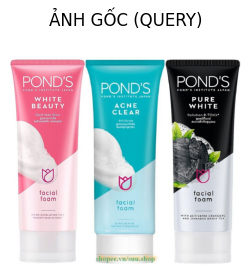

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


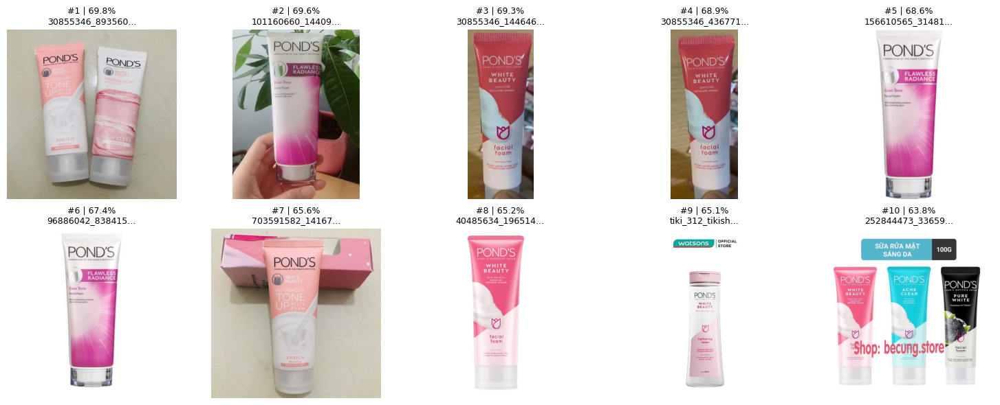

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: 40485634_1965140850.jpg
🎉 TUYỆT VỜI! Đáp án chuẩn nằm ở hạng #8 trong Top 10!


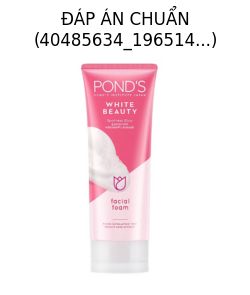

In [20]:
import os

row = df_result.iloc[0]

target_val = row['answer_product_id']
while isinstance(target_val, list):
    target_val = target_val[0]

ref_clean = os.path.basename(str(row['image_path']))
target_clean = os.path.basename(str(target_val))

searcher.evaluate_ground_truth(
    ref_id = ref_clean,
    target_id = target_clean,
    query_text = str(row['question']),
    top_k = 10
)

🔍 Đang thực hiện tìm kiếm cho query: "I need some gentle cotton pads like this for daily skincare, preferably 100% natural and not irritating to sensitive skin."


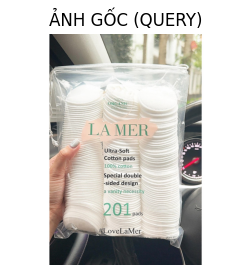

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


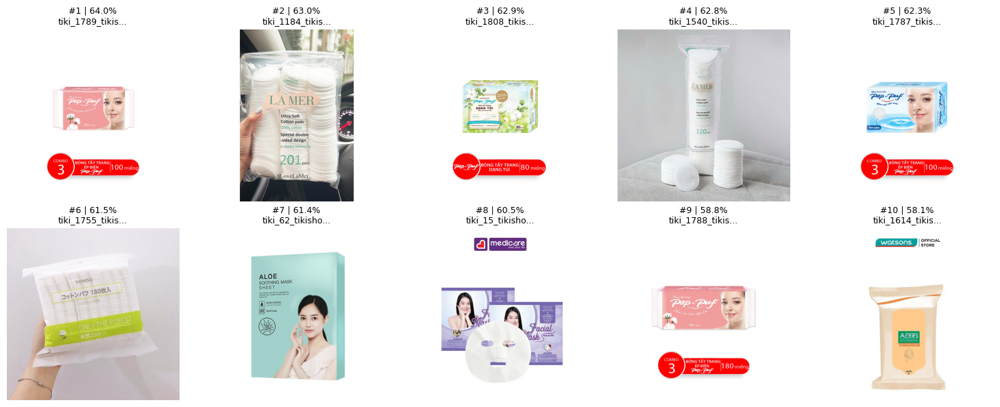

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: tiki_1540_tikishop_232_big.jpg
🎉 TUYỆT VỜI! Đáp án chuẩn nằm ở hạng #4 trong Top 10!


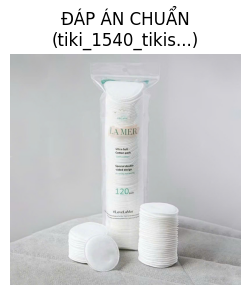

In [21]:
row = df_result.iloc[1]

target_val = row['answer_product_id']
while isinstance(target_val, list):
    target_val = target_val[0]


ref_clean = os.path.basename(str(row['image_path']))
target_clean = os.path.basename(str(target_val))

# 3. Truyền vào hàm đánh giá
searcher.evaluate_ground_truth(
    ref_id = ref_clean,
    target_id = target_clean,
    query_text = str(row['question']),
    top_k = 10
)

🔍 Đang thực hiện tìm kiếm cho query: "Is there a cleanser like this but with natural ingredients like avocado, around 30k for better hydration?"


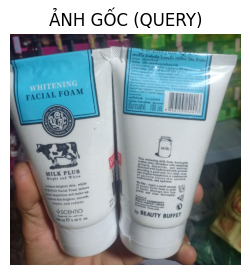

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


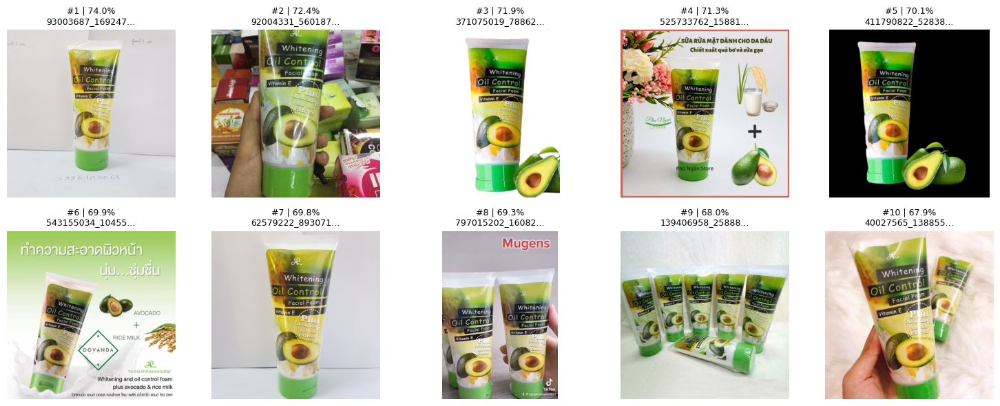

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: 81341396_1578921134.jpg
😭 Tiếc quá! Đáp án chuẩn KHÔNG LỌT VÀO Top 10.


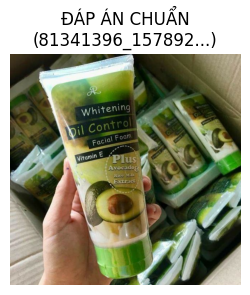

In [22]:
row = df_result.iloc[2]

target_val = row['answer_product_id']
while isinstance(target_val, list):
    target_val = target_val[0]

ref_clean = os.path.basename(str(row['image_path']))
target_clean = os.path.basename(str(target_val))

# 3. Truyền vào hàm đánh giá
searcher.evaluate_ground_truth(
    ref_id = ref_clean,
    target_id = target_clean,
    query_text = str(row['question']),
    top_k = 10
)

🔍 Đang thực hiện tìm kiếm cho query: "I've heard CeraVe is good for maintaining the skin barrier—do you have something like this for daily use?"


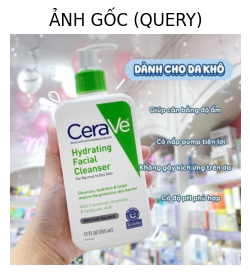

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


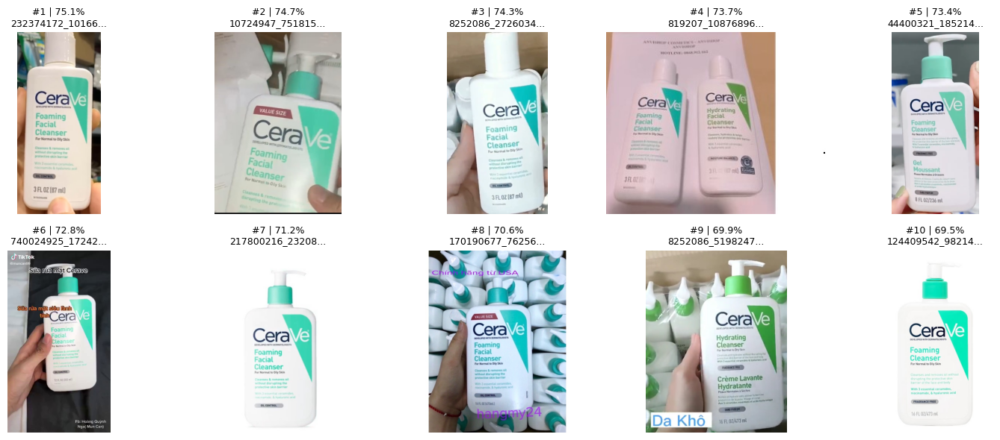

⚠️ Cảnh báo: Đáp án chuẩn 217800216_23208227697.mp4.jpg không có sẵn trong folder ảnh hiện tại.


In [23]:
row = df_result.iloc[3]

target_val = row['answer_product_id']
while isinstance(target_val, list):
    target_val = target_val[0]

ref_clean = os.path.basename(str(row['image_path']))
target_clean = os.path.basename(str(target_val))

# 3. Truyền vào hàm đánh giá
searcher.evaluate_ground_truth(
    ref_id = ref_clean,
    target_id = target_clean,
    query_text = str(row['question']),
    top_k = 10
)

🔍 Đang thực hiện tìm kiếm cho query: "I'm looking for a gel cleanser for oily, acne-prone skin that's soap-free and fragrance-free, that deeply cleanses sebum and effectively helps reduce acne, similar to Eucerin ProAcne, but I want to try other products that might be gentler or from other dermocosmetic brands in the 200k-300k VND price range."


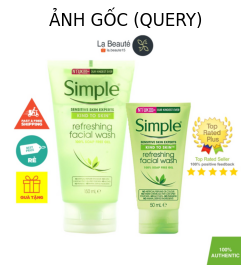

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


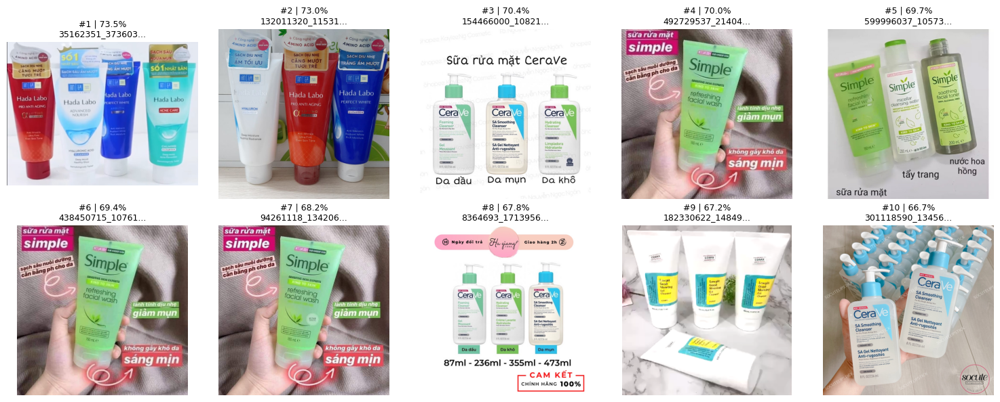

⚠️ Cảnh báo: Đáp án chuẩn 339.jpg không có sẵn trong folder ảnh hiện tại.


In [24]:
row = df_result.iloc[4]

target_val = row['answer_product_id']
while isinstance(target_val, list):
    target_val = target_val[0]

ref_clean = os.path.basename(str(row['image_path']))
target_clean = os.path.basename(str(target_val))

# 3. Truyền vào hàm đánh giá
searcher.evaluate_ground_truth(
    ref_id = ref_clean,
    target_id = target_clean,
    query_text = str(row['question']),
    top_k = 10
)

🔍 Đang thực hiện tìm kiếm cho query: "This looks nice, but do you have a more affordable amino acid cleanser that still cleans well and controls oil?"


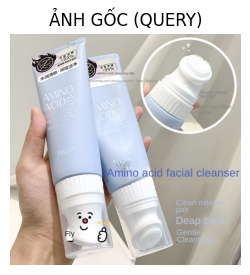

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


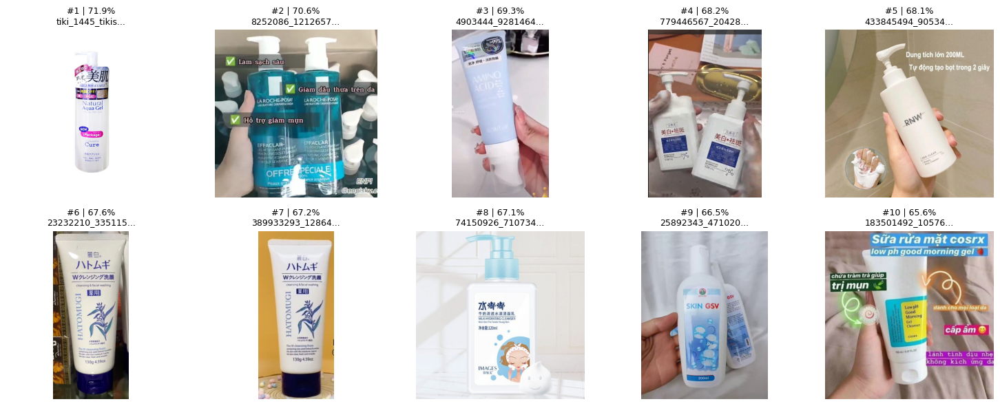

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: 8217147_18424418643.jpg
😭 Tiếc quá! Đáp án chuẩn KHÔNG LỌT VÀO Top 10.


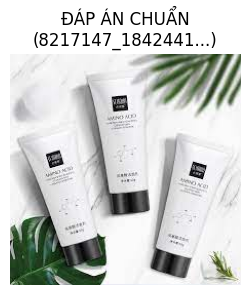

In [25]:
row = df_result.iloc[5]

target_val = row['answer_product_id']
while isinstance(target_val, list):
    target_val = target_val[0]

ref_clean = os.path.basename(str(row['image_path']))
target_clean = os.path.basename(str(target_val))

searcher.evaluate_ground_truth(
    ref_id = ref_clean,
    target_id = target_clean,
    query_text = str(row['question']),
    top_k = 10
)

🚀 BẮT ĐẦU CHẠY THỬ NGHIỆM...

📌 MẪU SỐ 1 / 20 | Index: 0
🔍 Đang thực hiện tìm kiếm cho query: "I'm looking for something similar but cheaper, around 40k–50k, preferably still from Pond’s."


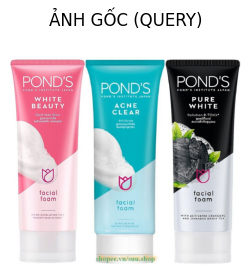

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


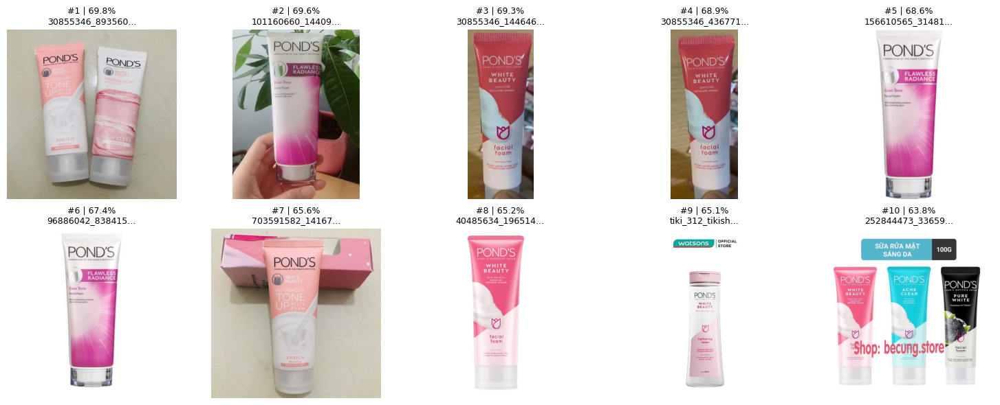

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: 40485634_1965140850.jpg
🎉 TUYỆT VỜI! Đáp án chuẩn nằm ở hạng #8 trong Top 10!


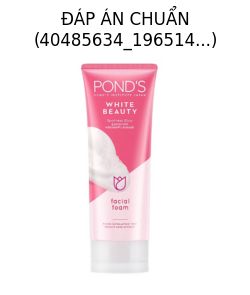



📌 MẪU SỐ 2 / 20 | Index: 1
🔍 Đang thực hiện tìm kiếm cho query: "I need some gentle cotton pads like this for daily skincare, preferably 100% natural and not irritating to sensitive skin."


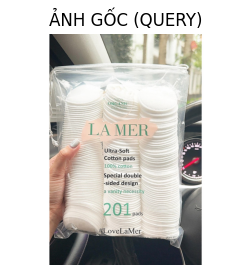

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


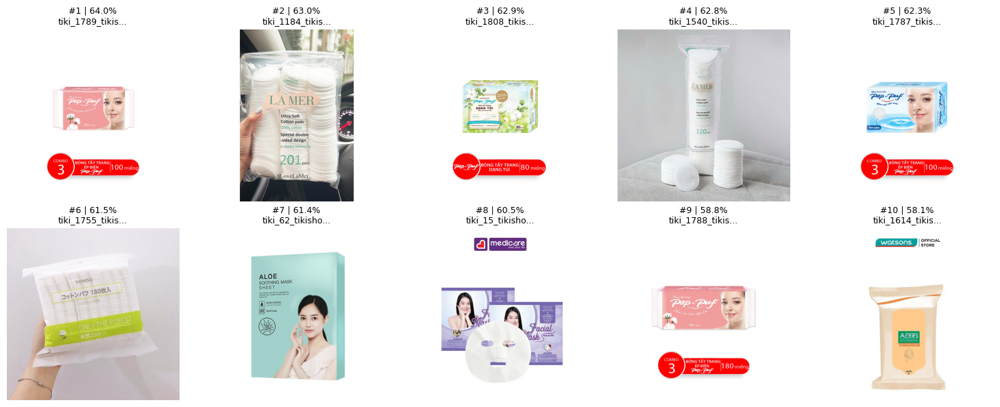

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: tiki_1540_tikishop_232_big.jpg
🎉 TUYỆT VỜI! Đáp án chuẩn nằm ở hạng #4 trong Top 10!


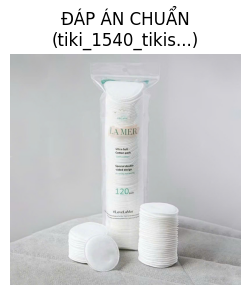



📌 MẪU SỐ 3 / 20 | Index: 2
🔍 Đang thực hiện tìm kiếm cho query: "Is there a cleanser like this but with natural ingredients like avocado, around 30k for better hydration?"


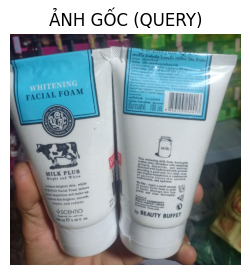

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


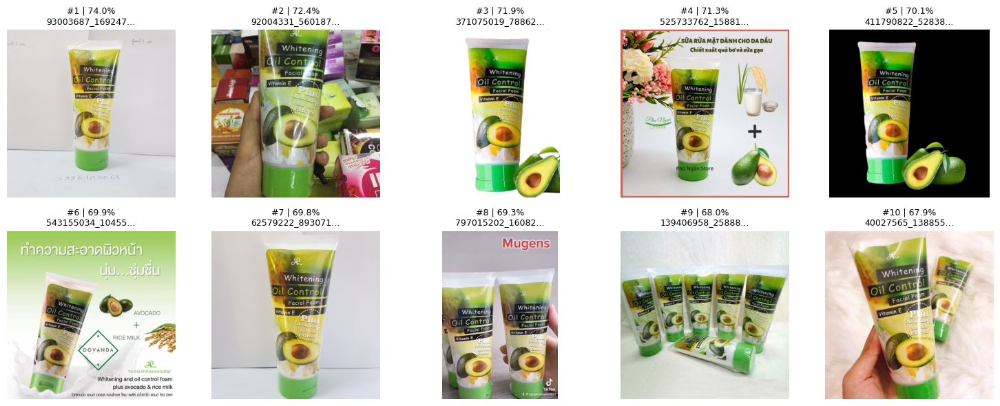

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: 81341396_1578921134.jpg
😭 Tiếc quá! Đáp án chuẩn KHÔNG LỌT VÀO Top 10.


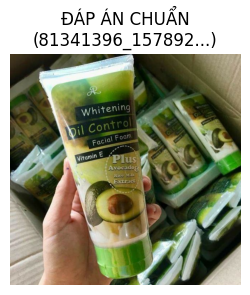



📌 MẪU SỐ 4 / 20 | Index: 3
🔍 Đang thực hiện tìm kiếm cho query: "I've heard CeraVe is good for maintaining the skin barrier—do you have something like this for daily use?"


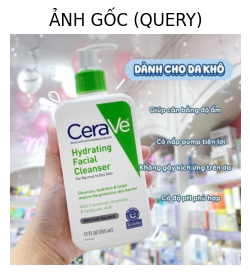

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


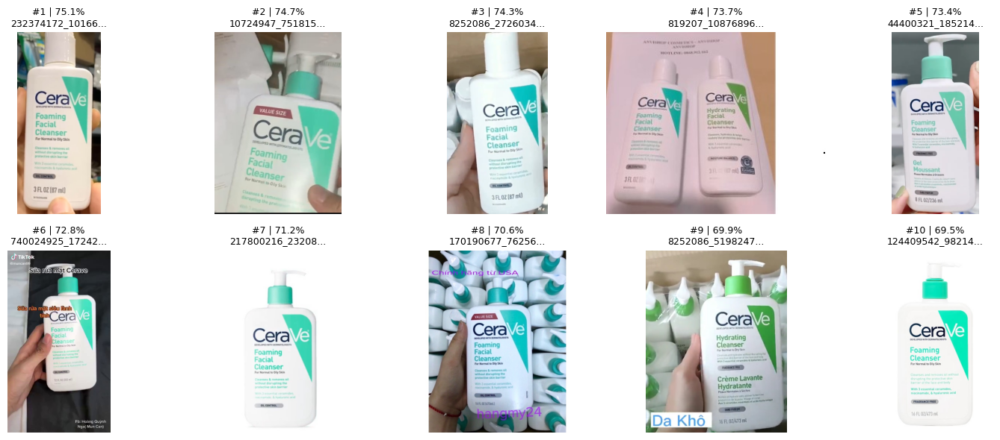

⚠️ Cảnh báo: Đáp án chuẩn 217800216_23208227697.mp4.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 5 / 20 | Index: 4
🔍 Đang thực hiện tìm kiếm cho query: "I'm looking for a gel cleanser for oily, acne-prone skin that's soap-free and fragrance-free, that deeply cleanses sebum and effectively helps reduce acne, similar to Eucerin ProAcne, but I want to try other products that might be gentler or from other dermocosmetic brands in the 200k-300k VND price range."


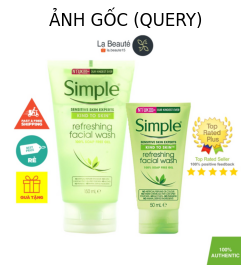

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


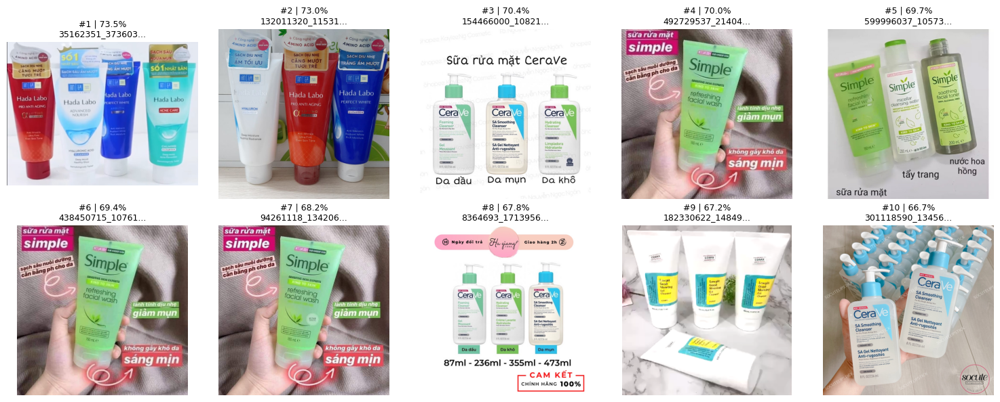

⚠️ Cảnh báo: Đáp án chuẩn 339.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 6 / 20 | Index: 5
🔍 Đang thực hiện tìm kiếm cho query: "This looks nice, but do you have a more affordable amino acid cleanser that still cleans well and controls oil?"


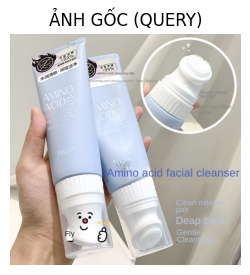

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


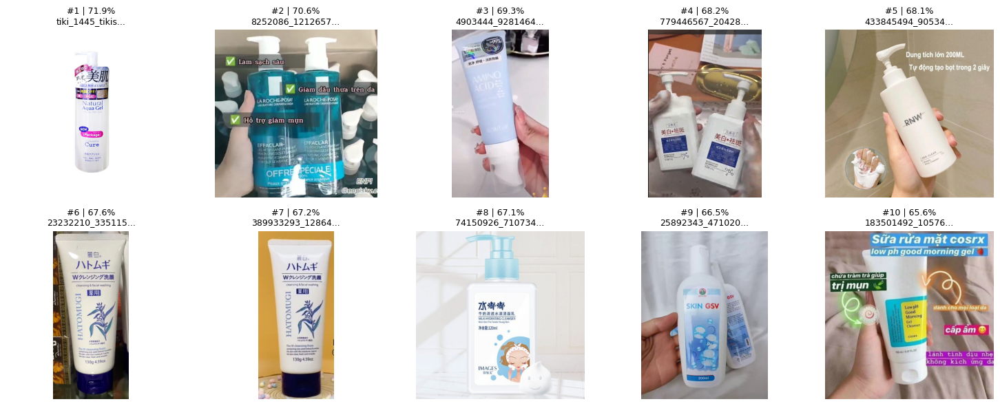

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: 8217147_18424418643.jpg
😭 Tiếc quá! Đáp án chuẩn KHÔNG LỌT VÀO Top 10.


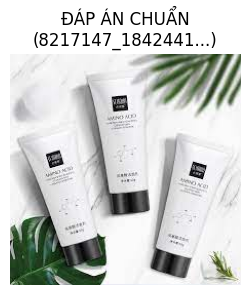



📌 MẪU SỐ 7 / 20 | Index: 6
🔍 Đang thực hiện tìm kiếm cho query: "I prefer well-known brands like NIVEA or Cetaphil. Do you have a gentle cleanser similar in quality to this product?"


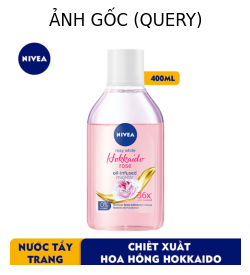

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


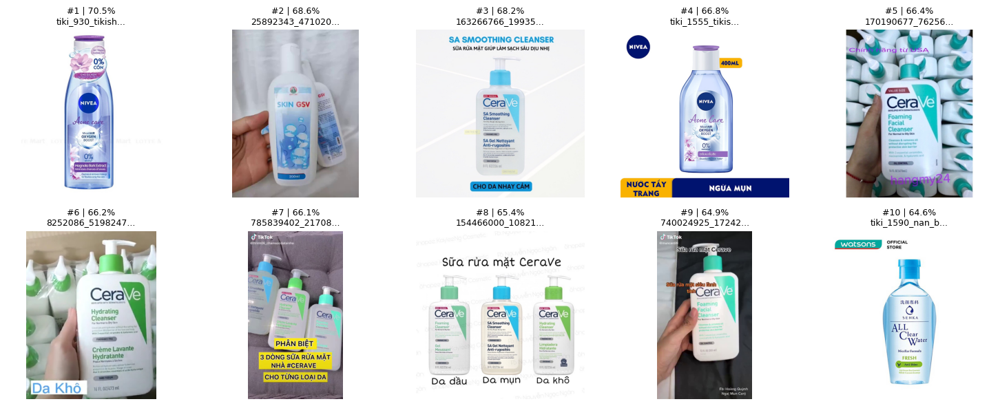

--------------------------------------------------
🎯 ĐÁP ÁN CHUẨN: 64099933_10161075948.jpg
😭 Tiếc quá! Đáp án chuẩn KHÔNG LỌT VÀO Top 10.


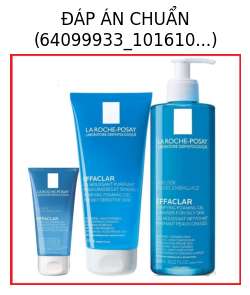



📌 MẪU SỐ 8 / 20 | Index: 7
🔍 Đang thực hiện tìm kiếm cho query: "I'm looking to buy a La Roche-Posay facial cleanser for oily, acne-prone skin that's gentle, pH 5.5, similar to the main product but a bit more affordable (around 200k VND or less). Are there any suitable options?"


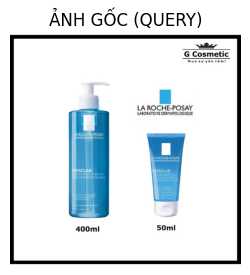

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


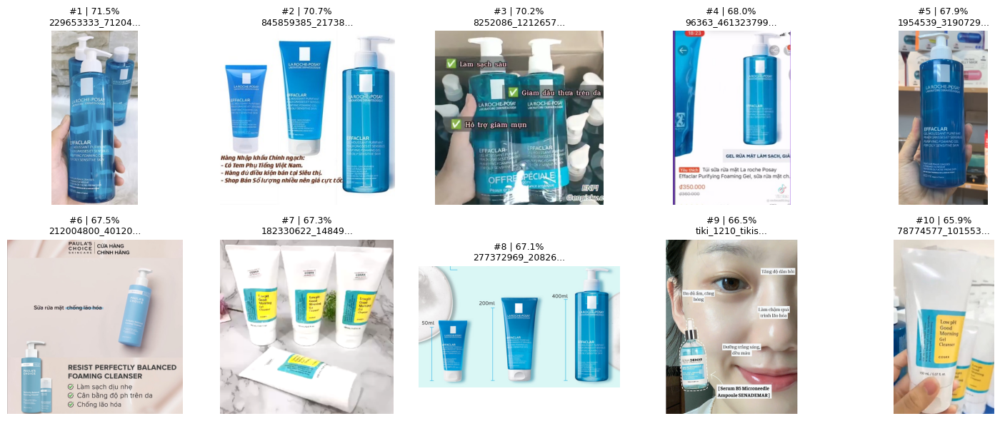

⚠️ Cảnh báo: Đáp án chuẩn 110.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 9 / 20 | Index: 8
🔍 Đang thực hiện tìm kiếm cho query: "I'm looking for a hydrating toner around 200k–300k VND that deeply moisturizes and soothes sensitive skin, preferably with natural marine ingredients like seaweed or minerals. Which products match this need?"


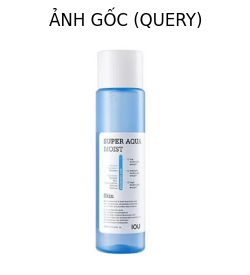

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


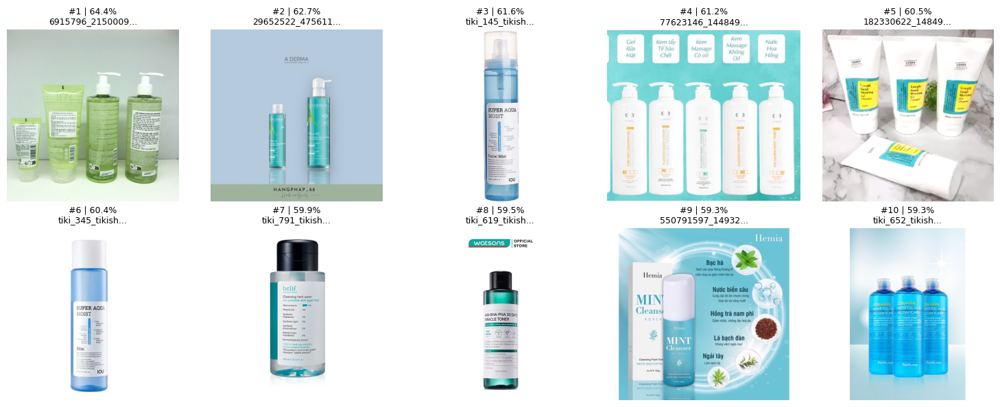

⚠️ Cảnh báo: Đáp án chuẩn tiki_325.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 10 / 20 | Index: 9
❌ Lỗi: Không tìm thấy ảnh gốc tại /kaggle/input/datasets/quanglapnguyen/cameo-images/cameo_images/348945140_13229186322.mp4.jpg


📌 MẪU SỐ 11 / 20 | Index: 10
🔍 Đang thực hiện tìm kiếm cho query: "I'm looking for a natural toner spray around 150k–200k with ingredients like aloe vera or herbal extracts that helps tighten pores, reduce acne, and can be used alone without combining with other skincare products—are there any alternatives similar to this?"


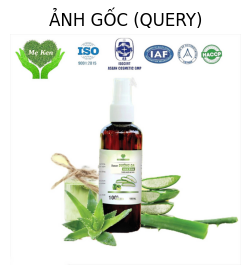

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


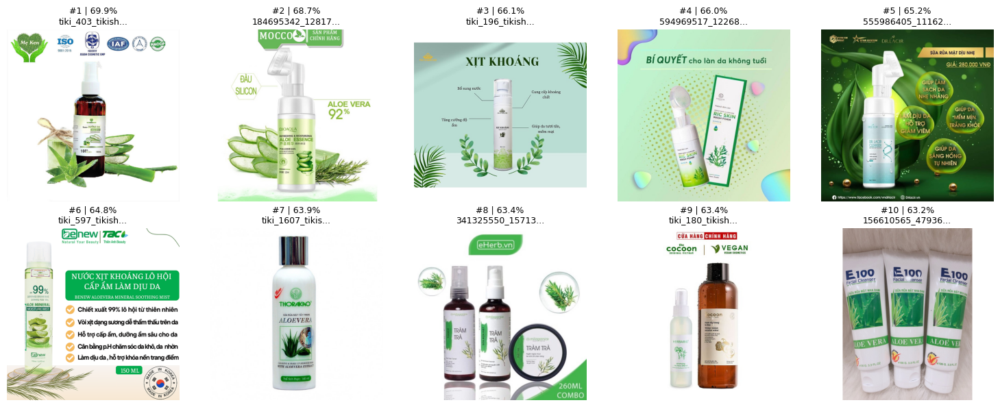

⚠️ Cảnh báo: Đáp án chuẩn tiki_405.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 12 / 20 | Index: 11
❌ Lỗi: Không tìm thấy ảnh gốc tại /kaggle/input/datasets/quanglapnguyen/cameo-images/cameo_images/295459902_6749033721.mp4.jpg


📌 MẪU SỐ 13 / 20 | Index: 12
🔍 Đang thực hiện tìm kiếm cho query: "I'm currently using a ~76,000 VND acne facial cleanser with BHA and dense foam for oily, acne-prone skin, but I want to switch to a different product that still deeply cleans pores and controls oil while being gentle and hydrating. Prefer products with ingredients like BHA or clay, from Japan or Korea, and priced under 120,000 VND. What are the best alternatives?"


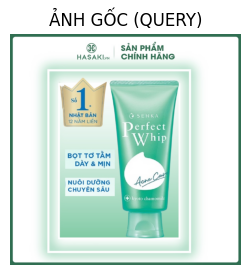

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


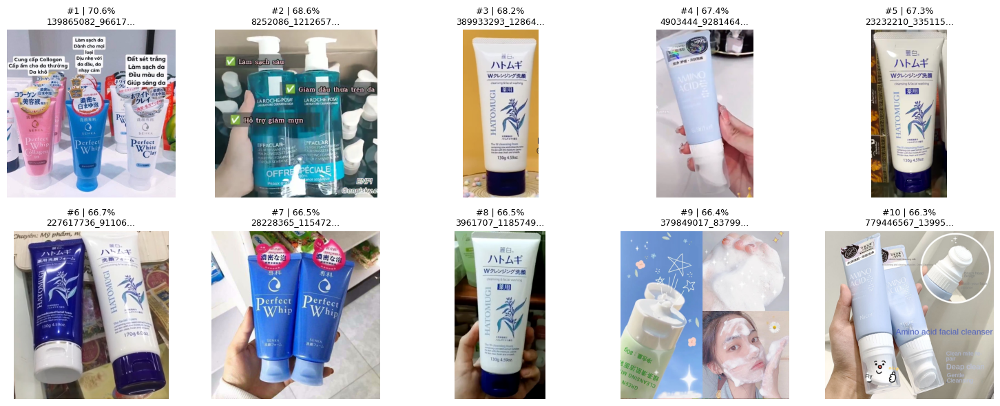

⚠️ Cảnh báo: Đáp án chuẩn 289.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 14 / 20 | Index: 13
🔍 Đang thực hiện tìm kiếm cho query: "I'm using a Vitamin A (retinol-derived) cream (~200,000 IU, ~200k VND) to improve fine lines and smooth my skin, but I want to find a different product that still targets anti-aging and boosts collagen while being more gentle and hydrating for daily use. Prefer products with retinol, niacinamide, or vitamin C, suitable for nighttime use, and priced around 150,000–400,000 VND. What are some good alternatives?"


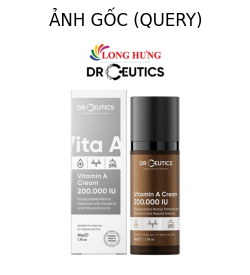

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


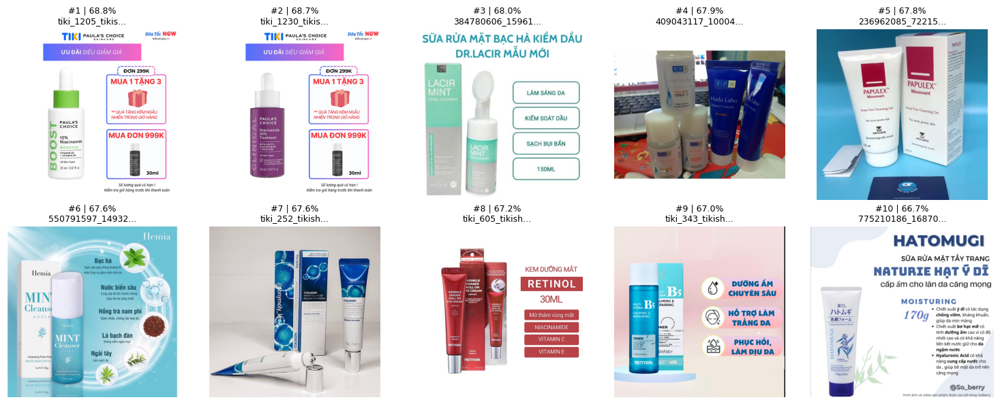

⚠️ Cảnh báo: Đáp án chuẩn tiki_1130.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 15 / 20 | Index: 14
🔍 Đang thực hiện tìm kiếm cho query: "I'm using a rice-based facial cleanser with natural extracts that helps moisturize and brighten my skin, but I want to try a different cleanser with natural ingredients like green tea, herbs, or plant extracts that can still deeply cleanse, control oil, and soothe the skin. It should be gentle enough for daily use and suitable for sensitive or acne-prone skin. What alternatives would you recommend?"


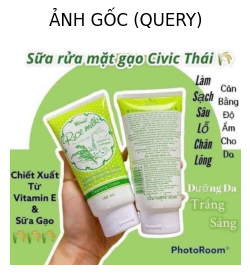

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


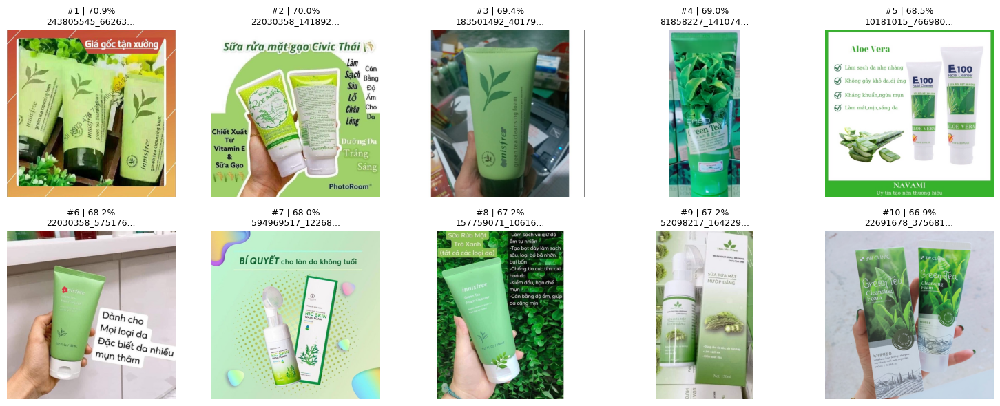

⚠️ Cảnh báo: Đáp án chuẩn 14.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 16 / 20 | Index: 15
🔍 Đang thực hiện tìm kiếm cho query: "I'm looking for a gentle facial cleansing gel with dermatological-grade ingredients that can better control oil and acne for sensitive skin, preferably something more clinically formulated rather than handmade."


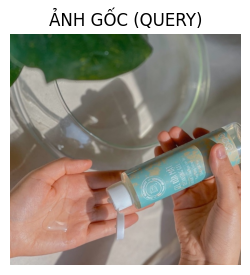

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


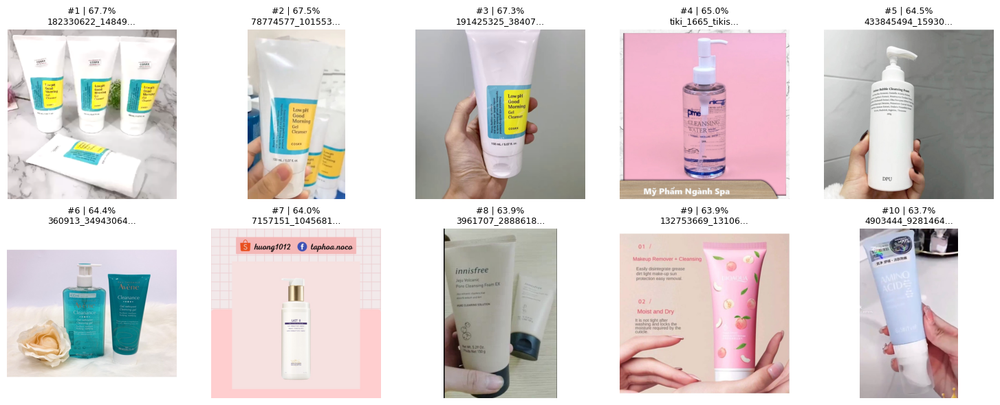

⚠️ Cảnh báo: Đáp án chuẩn 286.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 17 / 20 | Index: 16
🔍 Đang thực hiện tìm kiếm cho query: "I want the same gentle, soap-free Cetaphil cleanser but in a larger size for long-term daily use, still suitable for sensitive skin and maintaining moisture without irritation."


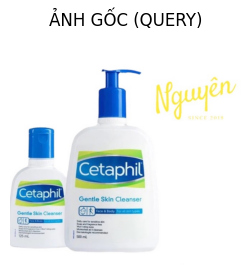

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


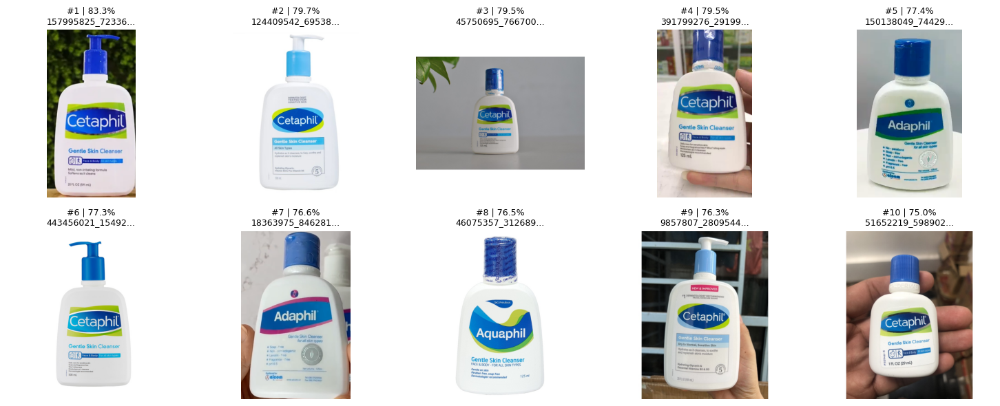

⚠️ Cảnh báo: Đáp án chuẩn 48.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 18 / 20 | Index: 17
🔍 Đang thực hiện tìm kiếm cho query: "I'm using a sunscreen with SPF50+ from Sắc Ngọc Khang, but my skin gets oily and shiny after a few hours—are there alternatives with similar UV/blue light protection and price range (~150k–260k), but better oil control or lighter textures like serum or spray?"


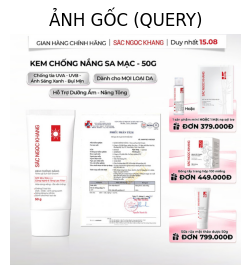

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


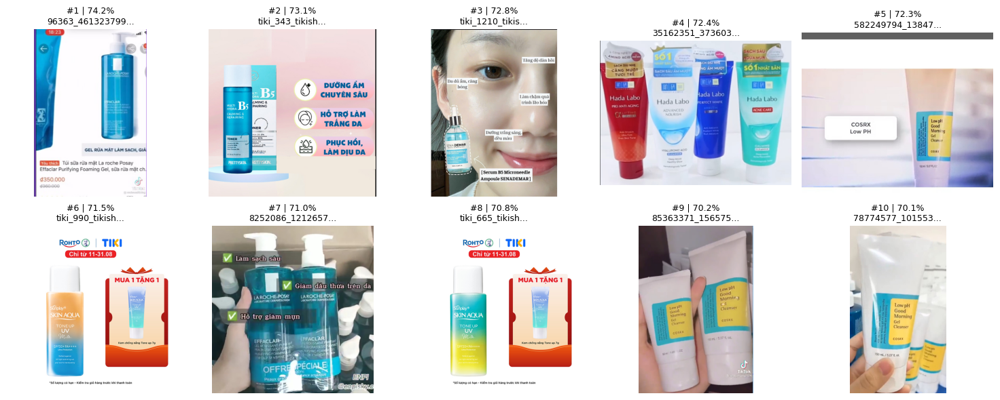

⚠️ Cảnh báo: Đáp án chuẩn tiki_456.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 19 / 20 | Index: 18
🔍 Đang thực hiện tìm kiếm cho query: "I'm currently using Queenie's collagen toner (priced around 350k VND) but I'm looking for a similar collagen-boosting or moisturizing/anti-aging product. I'd prefer something more affordable or with multiple uses (face mist/mask) for convenient daily skincare, and with good moisturizing ingredients like HA, retinol, or natural extracts."


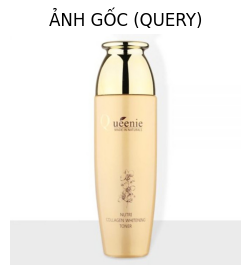

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


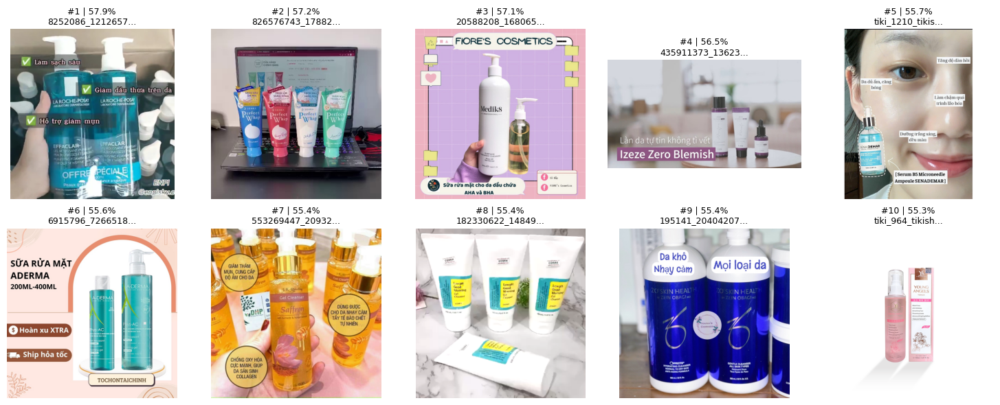

⚠️ Cảnh báo: Đáp án chuẩn tiki_157.jpg không có sẵn trong folder ảnh hiện tại.


📌 MẪU SỐ 20 / 20 | Index: 19
🔍 Đang thực hiện tìm kiếm cho query: "I'm looking for a foaming facial cleanser similar to Senka Perfect Whip from Japan, with silk extract or moisturizing ingredients (acids, collagen), that deeply cleanses sebum and dirt, suitable for oily or acne-prone skin, but at a lower price, under 60,000 VND."


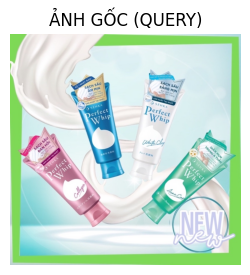

🌟 TOP 10 KẾT QUẢ TƯƠNG ĐỒNG NHẤT:


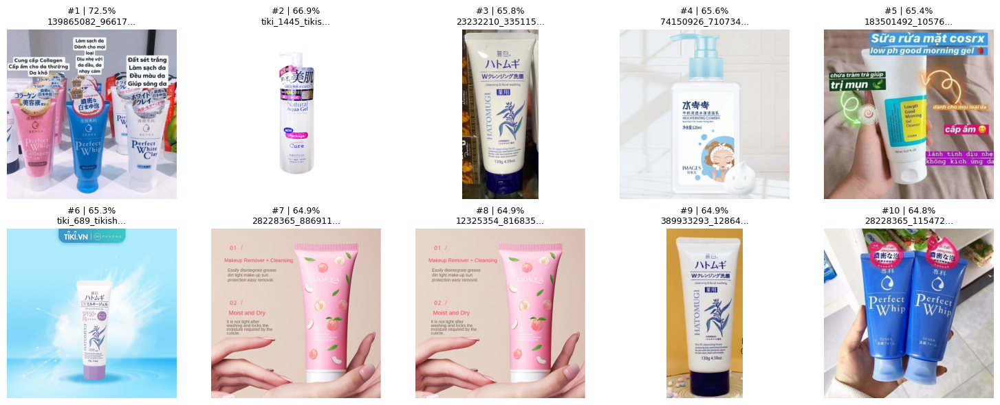

⚠️ Cảnh báo: Đáp án chuẩn 137.jpg không có sẵn trong folder ảnh hiện tại.


✨ ĐÃ HOÀN THÀNH CHẠY THỬ NGHIỆM!


In [26]:
import os
NUM_SAMPLES = len(df_result)

print(f"🚀 BẮT ĐẦU CHẠY THỬ NGHIỆM...\n")

# Vòng lặp duyệt qua 20 dòng đầu tiên của DataFrame
for idx, row in df_result.head(NUM_SAMPLES).iterrows():
    print("=" * 70)
    print(f"📌 MẪU SỐ {idx + 1} / {NUM_SAMPLES} | Index: {idx}")
    print("=" * 70)
    
    try:
        # 1. Bóc tách target_val nếu đang bị bọc trong list
        target_val = row['answer_product_id']
        while isinstance(target_val, list):
            target_val = target_val[0]

        # 2. Chuẩn hóa tên file (chỉ lấy phần tên sau dấu /)
        ref_clean = os.path.basename(str(row['image_path']))
        target_clean = os.path.basename(str(target_val))

        # 3. Gọi hàm tìm kiếm & đánh giá Top 10
        searcher.evaluate_ground_truth(
            ref_id = ref_clean,
            target_id = target_clean,
            query_text = str(row['question']),
            top_k = 10
        )
        print("\n")  # Tạo khoảng trống giữa các mẫu cho dễ nhìn
        
    except Exception as e:
        print(f"⚠️ Bỏ qua mẫu số {idx + 1} do gặp lỗi: {e}\n")

print("✨ ĐÃ HOÀN THÀNH CHẠY THỬ NGHIỆM!")

# FRAMEWORK + HÌNH 

In [27]:
import pandas as pd
import re

spreadsheet_id = '1h-CJhwfg_HcY2ftIc_rVIg3N7XemfHKXsUxbuOy_OYg'
sheet_gid =1495671440

# Construct the direct download URL for the CSV format, including the sheet gid
csv_url = f'https://docs.google.com/spreadsheets/d/{spreadsheet_id}/export?format=csv&gid={sheet_gid}'
# Read the CSV directly into a pandas DataFrame
try: 
    mincutev4 = pd.read_csv(csv_url)
    available_cols = ['product_id', 'image_path', 'product_name', 'translated_description', 'price', 'brand', 'origin', 'object', 'ingredient', 'capacity', 'purpose', 'type']
    mincutev4 = mincutev4[available_cols]
    display(mincutev4.shape)
    display(mincutev4.columns)
    for col in mincutev4.columns:
      print(col,end=": ")
      print(mincutev4[col].isna().sum())
except Exception as e:
    print(f"Error loading Google Sheet: {e}")
    print("Please ensure the spreadsheet ID is correct and the sheet is publicly accessible or shared with appropriate permissions.")

(4075, 12)

Index(['product_id', 'image_path', 'product_name', 'translated_description',
       'price', 'brand', 'origin', 'object', 'ingredient', 'capacity',
       'purpose', 'type'],
      dtype='object')

product_id: 0
image_path: 0
product_name: 0
translated_description: 18
price: 0
brand: 2
origin: 0
object: 0
ingredient: 437
capacity: 20
purpose: 0
type: 0


In [28]:
df= mincutev4.copy()
df

,product_id,image_path,product_name,translated_description,price,brand,origin,object,ingredient,capacity,purpose,type
0,0,111138057_8587034871.jpg,Simple Gentle & Refreshing Facial Cleanser - f...,Outstanding Advantages: Simple Facial Cleanser...,99000,Simple,Poland,sensitive skin,"Vitamin B5, Vitamin E, Pro Amino Acids",150ml,"Facial Cleanser, Facial Wash",cream form
1,1,111138057_8287055694.jpg,Simple Face Wash effectively controls oil and ...,Outstanding features: Simple facial cleanser h...,99000,Simple,Poland,"oily skin, acne skin","Hazel extract, plant-derived zinc (niacinamide)",150ml,"Face Wash, Facial cleanser, oil control, acne ...",gel form
2,2,21080428_9335942418.mp4,"30Shine Men's Face Wash, genuine Skin&dr Tea T...",Skin Dr Tea Tree Men's Facial Cleanser 80g for...,244000,Skin&Dr,South Korea,"acne skin, oily skin","Tea Tree, acids and glycolic acid from papaya,...",80g,"Face Wash Facial cleansing, fades dark spots, ...",cream form
3,3,758111427_19601743242.mp4,RHYS MAN Rhys Men's Facial Cleanser Coconut Fr...,Genuine Rhys Man Rhys Coconut Fresh Men's Faci...,119000,Rhys Man,Vietnam,"combination skin, men","Coconut, aloe vera, peppermint essential oil",100ml,Facial Cleanser,milk form
4,4,107632788_3330988133.jpg,🌈🍒🍭 Senana Facial Cleanser Deeply Cleanses Dir...,"Great wholesale price, only 13k! Best price gu...",9900,Senana,China,all skin types,NaN,60g,"Facial Cleanser Brightening, moisturizing, hyd...",cream form
...,...,...,...,...,...,...,...,...,...,...,...,...
4070,tiki_826,tiki_826_tikishop_41_big.jpg,Serum Compliment 2% BHA Salicylic Acid Hyaluro...,Product prices on Tiki include taxes according...,75000,Compliment,Russia,All skin types,"Vitamin C, Vitamin B5",27 ml,"Facial Cleanser cleans the skin, Reduces Acne,...",gel
4071,tiki_845,tiki_845_tikishop_180_big.jpg,Naruko – New skin brightening red essence – Sk...,"Product suitable for: All skin types, especial...",222130,Naruko,Taiwan,All skin types,Silk,25ml,brighten and moisturize dark skin mask,mask
4072,tiki_867,tiki_867_tikishop_28_big.jpg,Whoo Gold Gongjinhyang Neck & Face Sleeping Re...,- Provides moisture and necessary nutrients. H...,1170000,The Whoo,South Korea,All skin types,chemicals materials,75ml,anti-aging skin treatment mask,mask
4073,tiki_955,tiki_955_tikishop_149_big.jpg,NoTS ​​White Luminaire Revital Fluid 150ml,용도NoTS White Luminaire Revital Fluid 100ml is ...,880000,Nots,South Korea,All skin types,"Camellia Japonica, Rosa Centifolia, Licorice",150ml,skin whitening and moisturizing toner,liquid


In [29]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import re
model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [30]:
import pandas as pd
import ast

def parse_list_col(val):
    if pd.isna(val) or val == "" or val == "null":
        return None
    try:
        return ast.literal_eval(str(val))
    except:
        return val

try:
    df_parsed_questions = pd.read_csv(
        "/kaggle/input/datasets/nguynhngthominh/question/parsed_questions.csv", 
        encoding='latin1', 
        converters={
            "brand": parse_list_col,
            "price_range": parse_list_col
        }
    )
except UnicodeDecodeError:
    df_parsed_questions = pd.read_csv(
        "/kaggle/input/datasets/nguynhngthominh/question/parsed_questions.csv", 
        encoding='windows-1252',
        converters={
            "brand": parse_list_col,
            "price_range": parse_list_col
        }
    )

print(f"Đã tải thành công {len(df_parsed_questions)} câu hỏi từ file CSV!")

Đã tải thành công 20 câu hỏi từ file CSV!


In [31]:
import pandas as pd
import numpy as np
import os
import re
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_and_rank_hybrid(
    df_database, 
    ref_product_id, 
    parsed_row, 
    text_model, 
    magic_searcher=None,       # <-- Thêm object MagicLensSearcher
    ref_image_path=None,       # <-- Thêm đường dẫn ảnh gốc
    alpha=0.6,                 # <-- Trọng số: 0.6 cho Hình ảnh/MagicLens, 0.4 cho Text
    top_k=15
):
    """
    Hàm retrieval phân tầng kết hợp logic bảng (Tabular Filtering) + Text Embedding + MagicLens Visual Scoring.
    """
    ref_id = str(ref_product_id).split('.')[0].strip() 
    
    ref_rows = df_database[df_database['product_id'].astype(str).str.split('.').str[0].str.strip() == ref_id]
    if ref_rows.empty:
        print(f"--> [LỖI]: Không tìm thấy sản phẩm gốc với ID: {ref_id} trong df_database!")
        return pd.DataFrame()
        
    ref_product = ref_rows.iloc[0]

    brand_target = parsed_row.get("brand")
    origin_target = parsed_row.get("origin")
    price_range_raw = parsed_row.get("price_range")
    price_action = parsed_row.get("price_action")
    capacity_action = parsed_row.get("capacity_action")
    
    base_candidates = df_database[df_database['product_id'].astype(str).str.split('.').str[0].str.strip() != ref_id].copy()

    # =====================================================================
    # BƯỚC 1: LỌC THƯƠNG HIỆU & XUẤT XỨ (Giữ nguyên logic chuẩn hóa sạch)
    # =====================================================================
    if pd.notna(brand_target) and str(brand_target).lower() not in ['nan', 'null', '']:
        def clean_brand_string(s):
            s = str(s).lower()
            s = re.sub(r"[’’'\"\[\]]", "", s)
            return s.strip()

        if isinstance(brand_target, (str, list, np.ndarray)):
            if isinstance(brand_target, str):
                raw_brands = [b.strip() for b in brand_target.split(',')]
            else:
                raw_brands = [str(b) for b in brand_target]
            brand_clean_list = [clean_brand_string(b) for b in raw_brands if b.strip() != '']
            database_brands_clean = base_candidates['brand'].astype(str).apply(clean_brand_string)
            base_candidates = base_candidates[database_brands_clean.isin(brand_clean_list)]

    if pd.notna(origin_target) and str(origin_target).lower() not in ['nan', 'null', '']:
        base_candidates = base_candidates[base_candidates['origin'].astype(str).str.lower() == str(origin_target).lower()]

    # =====================================================================
    # BƯỚC 2: PHÂN TÁCH KHOẢNG GIÁ VÀ DUNG TÍCH (CAPACITY ACTION)
    # =====================================================================
    
     # =====================================================================
    # BƯỚC 2: PHÂN TÁCH KHOẢNG GIÁ VÀ DUNG TÍCH (CAPACITY ACTION)
    # =====================================================================
    def extract_capacity_value(capacity_str):
        if pd.isna(capacity_str): return None
        match = re.search(r'(\d+(?:\.\d+)?)\s*(ml|g|gram)', str(capacity_str).lower())
        if match:
            return float(match.group(1))
        return None

    if str(capacity_action).upper() == "LARGER":
        ref_cap = extract_capacity_value(ref_product.get('capacity'))
        if ref_cap is not None:
            def filter_larger_capacity(row):
                cand_cap = extract_capacity_value(row['capacity'])
                if cand_cap is not None:
                    return cand_cap > ref_cap
                return False
            base_candidates = base_candidates[base_candidates.apply(filter_larger_capacity, axis=1)]

    is_valid_price = False
    if price_range_raw is not None:
        if isinstance(price_range_raw, (np.ndarray, list)):
            is_valid_price = len(price_range_raw) > 0
        else:
            is_valid_price = pd.notna(price_range_raw)

    nums = [int(s) for s in re.findall(r'\d+', str(price_range_raw))] if is_valid_price else []

    price_min_strict, price_max_strict = None, None
    price_min_relaxed, price_max_relaxed = None, None

    # TÍNH TOÁN CÁC MỐC GIÁ
    if len(nums) == 1:
        if price_action == "CHEAPER" or "under" in str(parsed_row['question']).lower() or "less" in str(parsed_row['question']).lower():
            price_min_strict, price_max_strict = 0, int(nums[0])
            price_min_relaxed, price_max_relaxed = 0, int(nums[0] * 1.2)
        else:
            price_min_strict, price_max_strict = int(nums[0] * 0.9), int(nums[0] * 1.1)
            price_min_relaxed, price_max_relaxed = int(nums[0] * 0.8), int(nums[0] * 1.2)
            
    elif len(nums) >= 2:
        price_min_strict, price_max_strict = int(min(nums)), int(max(nums))
        price_min_relaxed, price_max_relaxed = int(min(nums) * 0.8), int(max(nums) * 1.2)

    elif price_action == "CHEAPER":
        price_min_strict, price_max_strict = 0, max(0, int(ref_product['price']) - 1)
        price_min_relaxed, price_max_relaxed = 0, max(0, int(ref_product['price'] * 1.2))
        
    elif price_action == "EXPENSIVE":
        price_min_strict, price_max_strict = int(ref_product['price']) + 1, float('inf')
        price_min_relaxed, price_max_relaxed = int(ref_product['price'] * 0.8), float('inf')

    # ---------------------------------------------------------------------
    # KHỐI LỌC ỨNG VIÊN ĐỒNG BỘ (Đoạn này bị thiếu gây ra lỗi của bạn đây!)
    # ---------------------------------------------------------------------
    if price_min_strict is not None and price_max_strict is not None:
        strict_candidates = base_candidates[
            (base_candidates['price'] >= price_min_strict) & (base_candidates['price'] <= price_max_strict)
        ].copy()
        
        relaxed_candidates = base_candidates[
            (base_candidates['price'] >= price_min_relaxed) & (base_candidates['price'] <= price_max_relaxed) &
            ~((base_candidates['price'] >= price_min_strict) & (base_candidates['price'] <= price_max_strict))
        ].copy()
    else:
        strict_candidates = base_candidates.copy()
        relaxed_candidates = pd.DataFrame()

    all_selected_candidates = pd.concat([strict_candidates, relaxed_candidates]).drop_duplicates(subset=['product_id'])

    if all_selected_candidates.empty:
        print("--> Không tìm thấy sản phẩm nào phù hợp kể cả sau khi nới giá!")
        return pd.DataFrame()

    # =====================================================================
    # BƯỚC 3: TÍNH ĐIỂM KẾT HỢP (HYBRID SCORING: TEXT + MAGICLENS)
    # =====================================================================
    def clean_val(v):
        if pd.isna(v) or str(v).lower() in ['nan', 'null', '']: return ""
        return str(v).replace('[', '').replace(']', '').replace("'", "")

    # 3.1. Tính điểm Text Embedding (Như cũ)
    ref_text_parts = [str(parsed_row['question'])]
    ref_text_parts.append(clean_val(parsed_row.get('object')))
    ref_text_parts.append(clean_val(parsed_row.get('purpose')))
    ref_text_parts.append(clean_val(parsed_row.get('target_ingredient')))
    ref_text_parts.append(clean_val(parsed_row.get('type')))
    
    ref_text = " . ".join([p for p in ref_text_parts if p.strip() != ''])
    ref_embedding = text_model.encode([ref_text])

    candidate_texts = (
        all_selected_candidates['product_name'].fillna('') + " . " +
        all_selected_candidates['type'].fillna('') + " . " +
        all_selected_candidates['object'].fillna('') + " . " +      
        all_selected_candidates['ingredient'].fillna('') + " . " +  
        all_selected_candidates['purpose'].fillna('')
    ).tolist()

    text_scores = cosine_similarity(ref_embedding, text_model.encode(candidate_texts))[0]
    
    # Chuẩn hóa min-max cho text_scores về dải [0, 1] để cộng cho chuẩn
    if text_scores.max() > text_scores.min():
        norm_text_scores = (text_scores - text_scores.min()) / (text_scores.max() - text_scores.min())
    else:
        norm_text_scores = text_scores

    all_selected_candidates['text_score'] = norm_text_scores

    # 3.2. Tính điểm MagicLens Visual Embedding (Nếu có truyền vào)
    if magic_searcher is not None and ref_image_path is not None and os.path.exists(ref_image_path):
        from PIL import Image
        import jax.numpy as jnp
        
        # Trích xuất vector của query (Ảnh gốc + Câu hỏi điều chỉnh)
        ref_img_obj = Image.open(ref_image_path).convert("RGB")
        query_vec = magic_searcher._get_vec(ref_img_obj, text=str(parsed_row['question']))
        
        # Lấy chỉ mục (index) của các candidate trong kho MagicLens
        cand_image_names = all_selected_candidates['image_path'].apply(lambda x: os.path.basename(str(x))).tolist()
        
        magic_scores = []
        for img_name in cand_image_names:
            # Tìm vị trí vector trong kho đã lưu của MagicLens
            try:
                # Tìm index của ảnh trong danh sách searcher.image_paths
                idx_in_magic = next(i for i, p in enumerate(magic_searcher.image_paths) if os.path.basename(p) == img_name)
                cand_vec = magic_searcher.all_vectors[idx_in_magic]
                # Dot product (vì vector đã normalize nên dot product = cosine similarity)
                score = float(jnp.dot(query_vec.flatten(), cand_vec.flatten()))
            except StopIteration:
                score = 0.0 # Nếu ảnh không có trong kho thì cho điểm 0
            magic_scores.append(score)
            
        magic_scores = np.array(magic_scores)
        # Chuẩn hóa min-max cho magic_scores
        if magic_scores.max() > magic_scores.min():
            norm_magic_scores = (magic_scores - magic_scores.min()) / (magic_scores.max() - magic_scores.min())
        else:
            norm_magic_scores = magic_scores
            
        all_selected_candidates['magic_score'] = norm_magic_scores
        
        all_selected_candidates['final_score'] = alpha * all_selected_candidates['magic_score'] + (1 - alpha) * all_selected_candidates['text_score']
    else:
        all_selected_candidates['final_score'] = all_selected_candidates['text_score']


    if relaxed_candidates.empty:
        print(f"--> [Kết quả phân tầng]: Đúng giá chuẩn: {len(strict_candidates)} | Giá nới lỏng: 0")
        final_output = all_selected_candidates.sort_values(by='final_score', ascending=False)
        return final_output.head(top_k)
        
    final_strict = all_selected_candidates[all_selected_candidates.index.isin(strict_candidates.index)].copy()
    final_relaxed = all_selected_candidates[all_selected_candidates.index.isin(relaxed_candidates.index)].copy()
                                                                                                        
    final_strict = final_strict.sort_values(by='final_score', ascending=False)
    final_relaxed = final_relaxed.sort_values(by='final_score', ascending=False)
    
    final_output = pd.concat([final_strict, final_relaxed])
    return final_output.head(top_k)

In [32]:
import os

query_row = df_parsed_questions.iloc[1]

print("❓ Câu hỏi:", query_row['question'])
print("🛍️ ID ảnh gốc:", query_row['product_id'])

ref_img_name = str(query_row.get('image_path', f"{query_row['product_id']}.jpg"))
ref_img_path = os.path.join("/kaggle/input/cameo-images/cameo_images", os.path.basename(ref_img_name))

top_candidates = retrieve_and_rank_hybrid(
    df_database = df,          
    ref_product_id = query_row['product_id'],
    parsed_row = query_row,              # Dòng câu hỏi đã parse
    text_model = model,                  # Mô hình embedding text (VD: SentenceTransformer)
    magic_searcher = searcher,         
    ref_image_path = ref_img_path,       
    alpha = 0.4,                         #40% hình ảnh + 60% văn bản
    top_k = 15
)

display(top_candidates[['product_id', 'product_name', 'price', 'final_score']])

print("Kết quả: ",df_result['answer'].iloc[1] )

❓ Câu hỏi: I need some gentle cotton pads like this for daily skincare, preferably 100% natural and not irritating to sensitive skin.
🛍️ ID ảnh gốc: tiki_1184
--> [Kết quả phân tầng]: Đúng giá chuẩn: 4074 | Giá nới lỏng: 0


,product_id,product_name,price,final_score
2754,tiki_333,Cotton Pad Abib Heartleaf Spot Pad Calming Tou...,345000,1.000000
2583,tiki_1820,Jomi cotton pad (Pack of 80),30000,0.993331
2521,tiki_1765,Combo Box of PUFFME Airlaid Skin Care cotton p...,102000,0.992263
3378,tiki_924,Cotton Pad Torriden Balanceful Toner Pad 60pcs...,486000,0.987567
2481,tiki_1540,"La Mer Organic Cotton Makeup Remover Pads, 120...",39000,0.982509
2842,tiki_424,Cotton Pad Cell Fusion C Cooling Pad Emergency...,441000,0.982295
3935,tiki_1642,Pharmacity Cotton Puffs (Box of 90 pieces) - New,32000,0.961718
2546,tiki_1788,"Combo POP-PUF Pressed cotton pad, 180 Pieces/Bag",90000,0.935150
2547,tiki_1789,"Combo POP-PUF Pressed cotton pad, 100 Pieces/Bag",63000,0.918092
2568,tiki_1807,Combo box of POP-PUF Airlaid Moisturizing cott...,90000,0.916911


Kết quả:  ['tiki_1540']


In [33]:
import os

query_row = df_parsed_questions.iloc[18]

print("❓ Câu hỏi:", query_row['question'])
print("🛍️ ID ảnh gốc:", query_row['product_id'])

ref_img_name = str(query_row.get('image_path', f"{query_row['product_id']}.jpg"))
ref_img_path = os.path.join("/kaggle/input/cameo-images/cameo_images", os.path.basename(ref_img_name))

top_candidates = retrieve_and_rank_hybrid(
    df_database = df,          
    ref_product_id = query_row['product_id'],
    parsed_row = query_row,              # Dòng câu hỏi đã parse
    text_model = model,                  # Mô hình embedding text (VD: SentenceTransformer)
    magic_searcher = searcher,         
    ref_image_path = ref_img_path,       
    alpha = 0.4,                         #40% hình ảnh + 60% văn bản
    top_k = 15
)

display(top_candidates)

print("Kết quả: ",df_result['answer'].iloc[18] )

❓ Câu hỏi: I'm currently using Queenie's collagen toner (priced around 350k VND) but I'm looking for a similar collagen-boosting or moisturizing/anti-aging product. I'd prefer something more affordable or with multiple uses (face mist/mask) for convenient daily skincare, and with good moisturizing ingredients like HA, retinol, or natural extracts.
🛍️ ID ảnh gốc: tiki_954


,product_id,image_path,product_name,translated_description,price,brand,origin,object,ingredient,capacity,purpose,type,text_score,final_score
1454,1632,218322104_6718826232.jpg,Collagen facial cleanser (stock available),"Collagen facial cleanser, 10 ml, for all skin ...",22999,Doleme,South Korea,all skin types,natural extracts,100g,"Facial Cleanser cleanse dirt and impurities, a...",foam form,1.000000,1.000000
1492,1707,540766923_9694247088.jpg,Senka Perfect Whip Collagen In Collagen Facial...,Senka Perfect Whip Collagen facial cleanser (1...,88000,Senka,Japan,all skin types,60 skincare ingredients,120G,"Facial Cleanser Deeply cleanse dirt and sebum,...",foam,0.966024,0.966024
3799,1980,191055262_3976074518.jpg,Senka Perfect Whip Collagen In Foaming Facial ...,Senka Perfect Whip Collagen-In Foaming Facial ...,69000,Senka,Japan,"aging, all skin types, dry, oily, sensitive","Collagen, white silk extract, double moisturiz...",120g,"Foaming Cleanser Cleanses skin, removes dirt a...",foam,0.941683,0.941683
3302,tiki_855,tiki_855_tikishop_16_big.jpg,Combo of 10 Dabo Collagen Korean Masks to prev...,Set of 10 pieces of Collagen mask to prevent a...,118000,Dabo,South Korea,All skin types,Animal,23g,anti-aging skin care,collagen mask,0.938860,0.938860
3776,1941,81341396_1573572245.jpg,Collagen facial cleanser,Collagen facial cleanser: Ingredients and Uses...,25000,Doleme,South Korea,"oily skin, combination skin, acne skin",collagen and natural ingredients,100ml,"Facial Cleanser cleansing, remove dead skin ce...",foam form,0.936654,0.936654
3322,tiki_874,tiki_874_tikishop_52_big.jpg,[Free 2 extra pieces] Set of 10 Dermal Collage...,Collagen nutritional masks help effectively pr...,140000,Dermal,South Korea,"Sensitive skin, Normal skin","Oyster, Vitamin E, retinol",10 pieces,anti-aging and brightening,sheet mask,0.933119,0.933119
132,132,140596179_17621977596.jpg,3W Clinic 100ml Facial Cleanser Collagen/Green...,3W Clinic facial cleanser comes in 5 types: ac...,22500,3W Clinic,South Korea,"oily, acne prone, aging skin","Collagen, Green Tea, Rose, Rice, Charcoal, barley",100ml,"Hydrates, moisturizes, removes makeup, Deeply ...",milk form,0.924240,0.924240
153,153,92004331_3949321196.jpg,Collagen facial cleanser,✅ Whitening product that regenerates skin cell...,20500,KB Pure,Israel,all skin types,Collagen,100ml,"Facial Cleanser whitening, regenerating skin, ...",cream form,0.923603,0.923603
831,831,85328813_3941833549.jpg,Korean Collagen skin care facial cleanser,sweat_droplets cherry_blossom sweat_droplets C...,22000,Doleme,China,all skin types,"Korean Collagen, lupin flower, natural extracts",100g,"Facial Cleanser, moisturizing, anti-aging, tig...",foam,0.921370,0.921370
1192,1192,40424985_1404101512.jpg,Collagen facial cleanser,Four-leaf Clover Collagen Facial Cleanser is s...,22999,Collagen,South Korea,all skin types,lupin flowers,100g,"Facial Cleanser Cleansing, moisture, softening...",foam form,0.899524,0.899524


Kết quả:  ['images/15/7_/tiki_157_tikishop_12_big.jpg', 'images/22/1_/tiki_221_tikishop_12_big.jpg', 'images/28/_t/tiki_28_tikishop_0_big.jpg', 'images/15/3_/tiki_153_tikishop_57_big.jpg']


In [34]:

NUM_QUERIES =  len(df_parsed_questions)

IMAGE_FOLDER = "/kaggle/input/cameo-images/cameo_images"

for idx, query_row in tqdm(df_parsed_questions.head(NUM_QUERIES).iterrows(), total=NUM_QUERIES):
    print("=" * 80)
    print(f"📌 CÂU HỎI SỐ {idx + 1} / {NUM_QUERIES} | ID gốc: {query_row['product_id']}")
    print(f"❓ Query: {query_row['question']}")
    print("=" * 80)
    
    try:
        ref_img_name = str(query_row.get('image_path', f"{query_row['product_id']}.jpg"))
        ref_img_path = os.path.join(IMAGE_FOLDER, os.path.basename(ref_img_name))
        
        # 2. Gọi hàm Hybrid Retrieval
        top_candidates = retrieve_and_rank_hybrid(
            df_database = df,          
            ref_product_id = query_row['product_id'],
            parsed_row = query_row,              
            text_model = model,                  
            magic_searcher = searcher,         
            ref_image_path = ref_img_path,       
            alpha = 0.4,                         # 40% hình ảnh + 60% văn bản
            top_k = 10
        )
        
        if not top_candidates.empty:
            display(top_candidates[['product_id', 'product_name', 'price', 'final_score']])
        else:
            print("❌ Bộ lọc không trả về kết quả nào cho câu này!")
            
        expected_ans = df_result['answer'].iloc[idx] if idx < len(df_result) else "Không có dữ liệu đối chiếu"
        print(f"🎯 Đáp án chuẩn bên df_result: {expected_ans}\n\n")
        
    except Exception as e:
        print(f"⚠️ Bỏ qua câu hỏi số {idx + 1} do gặp lỗi: {e}\n\n")

print("✨ ĐÃ HOÀN THÀNH CHẠY PIPELINE!")

  0%|          | 0/20 [00:00<?, ?it/s]

📌 CÂU HỎI SỐ 1 / 20 | ID gốc: 590
❓ Query: I'm looking for something similar but cheaper, around 40k50k, preferably still from Ponds.


,product_id,product_name,price,final_score
1249,1249,Pond's White Beauty Brightening Facial Cleanser,48000,0.745433
1525,1761,Pond's Pink Brightening Facial Cleanser (100g),45500,0.506746
1374,1509,Pond's White Beauty Daily Brightening Facial C...,40000,0.236754
1235,1235,Pon'd Facial Cleanser 50g and 100g,47000,0.191880
304,304,Pond's Pink Facial Cleanser 100g,53000,1.000000
497,497,Pond's Brightening Facial Cleanser 100g (new s...,58800,0.866734
844,844,Ponds Flawless White Facial Cleanser 50g,32500,0.789413
3670,1684,[NEW] Pond's White Beauty Radiant Pinkish Whit...,55000,0.756944
412,412,Pond's White Beauty Whitening Facial Cleanser ...,56000,0.753560
1383,1518,Pond's White Beauty Skin Brightening Facial Cl...,59000,0.642808


🎯 Đáp án chuẩn bên df_result: ['1509', '1352']


📌 CÂU HỎI SỐ 2 / 20 | ID gốc: tiki_1184
❓ Query: I need some gentle cotton pads like this for daily skincare, preferably 100% natural and not irritating to sensitive skin.
--> [Kết quả phân tầng]: Đúng giá chuẩn: 4074 | Giá nới lỏng: 0


,product_id,product_name,price,final_score
2754,tiki_333,Cotton Pad Abib Heartleaf Spot Pad Calming Tou...,345000,1.000000
2583,tiki_1820,Jomi cotton pad (Pack of 80),30000,0.993331
2521,tiki_1765,Combo Box of PUFFME Airlaid Skin Care cotton p...,102000,0.992263
3378,tiki_924,Cotton Pad Torriden Balanceful Toner Pad 60pcs...,486000,0.987567
2481,tiki_1540,"La Mer Organic Cotton Makeup Remover Pads, 120...",39000,0.982509
2842,tiki_424,Cotton Pad Cell Fusion C Cooling Pad Emergency...,441000,0.982295
3935,tiki_1642,Pharmacity Cotton Puffs (Box of 90 pieces) - New,32000,0.961718
2546,tiki_1788,"Combo POP-PUF Pressed cotton pad, 180 Pieces/Bag",90000,0.935150
2547,tiki_1789,"Combo POP-PUF Pressed cotton pad, 100 Pieces/Bag",63000,0.918092
2568,tiki_1807,Combo box of POP-PUF Airlaid Moisturizing cott...,90000,0.916911


...

🎯 Đáp án chuẩn bên df_result: ['images/45/6_/tiki_456_tikishop_71_big.jpg', 'images/46/0_/tiki_460_tikishop_2_big.jpg', 'images/50/2_/tiki_502_tikishop_56_big.jpg', 'images/53/4_/tiki_534_tikishop_131_big.jpg']


📌 CÂU HỎI SỐ 19 / 20 | ID gốc: tiki_954
❓ Query: I'm currently using Queenie's collagen toner (priced around 350k VND) but I'm looking for a similar collagen-boosting or moisturizing/anti-aging product. I'd prefer something more affordable or with multiple uses (face mist/mask) for convenient daily skincare, and with good moisturizing ingredients like HA, retinol, or natural extracts.


,product_id,product_name,price,final_score
1454,1632,Collagen facial cleanser (stock available),22999,1.000000
1492,1707,Senka Perfect Whip Collagen In Collagen Facial...,88000,0.966024
3799,1980,Senka Perfect Whip Collagen In Foaming Facial ...,69000,0.941683
3302,tiki_855,Combo of 10 Dabo Collagen Korean Masks to prev...,118000,0.938860
3776,1941,Collagen facial cleanser,25000,0.936654
3322,tiki_874,[Free 2 extra pieces] Set of 10 Dermal Collage...,140000,0.933119
132,132,3W Clinic 100ml Facial Cleanser Collagen/Green...,22500,0.924240
153,153,Collagen facial cleanser,20500,0.923603
831,831,Korean Collagen skin care facial cleanser,22000,0.921370
1192,1192,Collagen facial cleanser,22999,0.899524


🎯 Đáp án chuẩn bên df_result: ['images/15/7_/tiki_157_tikishop_12_big.jpg', 'images/22/1_/tiki_221_tikishop_12_big.jpg', 'images/28/_t/tiki_28_tikishop_0_big.jpg', 'images/15/3_/tiki_153_tikishop_57_big.jpg']


📌 CÂU HỎI SỐ 20 / 20 | ID gốc: 750
❓ Query: I'm looking for a foaming facial cleanser similar to Senka Perfect Whip from Japan, with silk extract or moisturizing ingredients (acids, collagen), that deeply cleanses sebum and dirt, suitable for oily or acne-prone skin, but at a lower price, under 60,000 VND.


,product_id,product_name,price,final_score
277,277,Senka Perfect Whip Foaming Facial Cleanser wit...,39500,1.000000
1074,1074,Perfect Whip Japanese Facial Cleanser,29000,0.972089
595,595,Senka Perfect Whip Facial Cleanser 120g - Japan,58000,0.873098
1446,1617,SENKA Perfect Whip Facial Cleanser 120g,29999,0.848820
137,137,Senka Perfect Whip Foaming Facial Cleanser NEW...,35000,0.796923
919,919,NEW MODEL Perfect Whip Facial Cleanser 120g – ...,49000,0.795436
964,964,Senka Perfect Whip Facial Cleanser 120g - Japan,45000,0.756500
1552,1788,[NEW 2021 VERSION] Shiseido Senka Perfect Whip...,59000,0.735920
214,214,"Senka Facial Cleanser from Japan, 120g, availa...",55000,0.697431
262,262,[New 2021 Model] Senka Perfect Whip Foaming Cl...,59000,0.674488


🎯 Đáp án chuẩn bên df_result: ['images/16/32/163266766_21403983819.jpg', 'images/59/71/597157193_15103510214.mp4', 'images/84/72/84728643_10404575253.jpg', 'images/10/28/102812033_10065758548.jpg', 'images/26/49/264988200_8074162673.jpg']


✨ ĐÃ HOÀN THÀNH CHẠY PIPELINE!
